#### FFW SG2 - Motion Executor, **Cartesian (EEF) interpolation**

A variant of `sim_motion_executor_test.ipynb`. Same scene, same wrist gizmos, same command
window, same output stage -- **the route between two poses is what changes**.

| | `sim_motion_executor_test.ipynb` | this notebook |
|---|---|---|
| interpolated quantity | joint angles | the wrist **pose** |
| planner | `plan_min_jerk` | `plan_cartesian_wrist` (defined below) |
| IK | only for `shut_down`'s single lift goal | at every knot along the path |
| wrist path | whatever FK makes of a joint-space line | a straight line + a rotation geodesic |
| arrives at | exactly `q_goal` | *a* pose with the right wrist frame, **not** `q_goal` |

**Why this exists.** `plan_min_jerk` interpolates in joint space, `q(u) = q_0 + u*dq`. That is a
straight line in *joint* space; its image under FK is a curve, and the deviation from the straight
Cartesian line grows as the *square* of `|dq|`. For a small move it is invisible; for the 30-50 cm
`wrist_lift` leg of `shut_down` it is the difference between "the hand comes straight up out of
what it was holding" and "the hand swings out through the table on its way up".

**How it works -- path and time are solved separately.**

1. **Path.** Read the wrist poses at `q_start` and `q_goal` by FK. Sweep a parameter `u` from 0 to
   1, and at each of `CART_N_KNOT` knots put the wrist at `p(u) = p_0 + u*(p_1 - p_0)` with
   `R(u) = R_0 * exp(u * log(R_0^T R_1))` (a geodesic, via `r2w` / `w2r`), solve IK warm-started
   from the previous knot, and record the joint pose. Fit those knots with a C2 cubic spline
   `q(u)`. The lift and head joints, which no IK owns, are carried along the same `u` **before**
   each solve -- `lift_joint` raises the whole torso, so solving the arms against a stale lift
   value would put the wrist somewhere else entirely.
2. **Time.** Lay a min-jerk `s(t)` over that path: `q(t) = q(s(t))`. The duration is the larger of
   what the Cartesian ceilings (`CART_LIN_SPEED_MAX`, `CART_ANG_SPEED_MAX`) allow and what the
   joint ceilings allow. Stretching `T` by a factor `c` divides every joint velocity by `c` and
   every acceleration by `c^2` **exactly** -- the path is untouched, only the clock stretches -- so
   the required factor is measured once on a dense grid and applied, with no iteration and none of
   the slack an analytic bound would leave.

All of this happens **at plan time**, not in the control loop: the loop still consumes a
precomputed `qpos` array one row per tick, exactly as before, and `tick()` is not overridden.

**The catch you must read the numbers for.** A 7-DoF arm has a null space, so the pose the IK
lands on at `u=1` has the right wrist frame but is **not** `q_goal` -- the offline cell reports
this as `endpoint gap`, and it reaches tens of degrees on the fold-in legs. That is fine for
`wrist_lift`, whose goal only ever *meant* "put the wrist here". It is not fine for `start` or
`step1`, which are stow poses where the elbow angle is the point. `CARTESIAN_SEGMENTS` in the
planner cell is the knob: set it to `{"wrist_lift"}` to route only the leg that is genuinely a
Cartesian instruction and leave the stow poses on the joint-space planner.

Planning costs roughly 5 ms per knot per arm, so a `CART_N_KNOT` of 120 is about a second of
freeze when a segment is planned. Segments are planned lazily, one at a time, so that cost lands
*during* the motion rather than all at once at the start.

In [33]:
%run ../package/init_project.py

import numpy as np
from scipy.interpolate import CubicSpline   # C2 path fit for the Cartesian planner

from ri_motion_v5_package.init_scripts.init_ipython_setup import *
from ri_motion_v5_package.init_scripts.init_qt import *
from ri_motion_v5_package.mujoco_sim import *
from ri_motion_v5_package.kinematics import *
from ri_motion_v5_package.utility import *
from ri_motion_v5_package.qt import *
from utils import *
from package.joint_control import *        # not `from joint_control import *`: IPython's %run puts
from package.joint_marker_control import * # PACKAGE_DIR on sys.path only during the run
from package.joint_marker_real import *    # speed limits + apply_sg2_joint_rate_limit
from package.motion_executor import *      # min-jerk planner, SG2MotionExecutor, bring-up waypoints

app = get_qt_app()


[ffw_sg2_vr_teleoperation] initialized.
 - PROJECT_DIR: /Users/yongjoo/dev/VAI_AIWORKER/ri_motion_v5_VR/project/ffw_sg2_vr_teleoperation


<Figure size 640x480 with 0 Axes>

In [34]:
xml_path = merge_mjcfs(
    included_mjcf_files = [
        str(FLOOR_XML_PATH),
        str(SG2_XML_PATH),
        str(SG2_PROJECT_XML_DIR / "table.xml"),  # same scene as sim_joint_controller_sg2_teleop_with_table
    ],
    output_xml_path = str(SG2_SCENE_XML_PATH),)
env = MuJoCoParser(rel_xml_path=xml_path,verbose=False)
env.reset()
env.set_p("base_link","body",(0.0,0.0,0.01))

# Bend the elbows into a natural pose so both wrists start away from IK singularities.
'''env.forward(
    q           = [np.deg2rad(-90.0),np.deg2rad(-90.0)],
    joint_names = ["arm_l_joint4","arm_r_joint4"],)'''

env.forward(
    q = np.deg2rad([-37.26, +18.04, -28.89, -21.94, +34.86, -33.99,  -4.56,   # left  1..7
                    +25.04, -22.18,  +2.38, -83.38, -22.72, -31.96,  +0.58]), # right 1..7
    joint_names = ["arm_l_joint%d" % i for i in range(1, 8)] + ["arm_r_joint%d" % i for i in range(1, 8)],)


# Same joint set the real robot takes over ZMQ: lift + head + both arms + both gripper drivers.
# The executor works in this order throughout; note it differs from the arm-only IK joint order.
command_joint_names = filter_existing_joint_names(
    env,
    list(SG2_REAL_COMMAND_JOINT_NAMES)
    + [SG2_GRIPPER_DRIVER_JOINT_NAMES[hand_type] for hand_type in SG2_HAND_TYPES],)
print(f"command joints ({len(command_joint_names)}): {command_joint_names}")

[merge_mjcfs] Merging [3] MJCF files:
  - [0] [/Users/yongjoo/dev/VAI_AIWORKER/ri_motion_v5_VR/project/ffw_sg2_vr_teleoperation/xml/floor_simple_white.xml]
  - [1] [/Users/yongjoo/dev/VAI_AIWORKER/ri_motion_v5_VR/project/ffw_sg2_vr_teleoperation/xml/ffw_sg2.xml]
  - [2] [/Users/yongjoo/dev/VAI_AIWORKER/ri_motion_v5_VR/project/ffw_sg2_vr_teleoperation/xml/table.xml]
[merge_mjcfs] Saved merged XML to:[/Users/yongjoo/dev/VAI_AIWORKER/ri_motion_v5_VR/project/ffw_sg2_vr_teleoperation/xml/scene_ffw_sg2_metaquest3.xml]
MuJoCo model loaded from [/Users/yongjoo/dev/VAI_AIWORKER/ri_motion_v5_VR/project/ffw_sg2_vr_teleoperation/xml/scene_ffw_sg2_metaquest3.xml].
command joints (19): ['lift_joint', 'head_joint1', 'head_joint2', 'arm_l_joint1', 'arm_l_joint2', 'arm_l_joint3', 'arm_l_joint4', 'arm_l_joint5', 'arm_l_joint6', 'arm_l_joint7', 'arm_r_joint1', 'arm_r_joint2', 'arm_r_joint3', 'arm_r_joint4', 'arm_r_joint5', 'arm_r_joint6', 'arm_r_joint7', 'gripper_l_joint1', 'gripper_r_joint1']


In [35]:
# One small (non-collision-aware) DLS IK solver per arm, each restricted to that arm's joints.
ik_solvers,arm_joint_names = create_sg2_arm_ik_solvers(
    env                = env,
    mujoco_parser_cls  = MuJoCoParser,
    body_ik_solver_cls = BodyPositionIKSolverRevPriBase,)
for hand_type in SG2_HAND_TYPES:
    print(f"{hand_type} arm IK joints ({len(arm_joint_names[hand_type])}): {arm_joint_names[hand_type]}")

# Collision is only monitored here: signed distances are reported, never corrected.
# The candidate pairs are "one geom on the robot vs any other collision geom", so with
# table.xml merged into the scene the robot-vs-table pairs come along for free -- the
# same call now covers self-collision AND the table.
collision_geom_pairs,collision_candidate_info = create_sg2_collision_candidate_geom_pairs(
    env               = env,
    init_exclude_dist = 0.05,)
print_sg2_collision_candidate_summary(collision_candidate_info)

# Split the candidates into self-collision and robot-vs-table, so it is visible that the
# table actually entered the set (an empty table row means the merge or the pose filter
# dropped it, and the run would then report "safe" while an arm goes through the top).
table_geom_idxs = set(env.get_geom_idxs_from_root_body_name("table"))
env_pair_idxs   = [i for i,(g1,g2) in enumerate(collision_geom_pairs)
                   if int(g1) in table_geom_idxs or int(g2) in table_geom_idxs]
print("  self-collision pairs:[%d]" % (len(collision_geom_pairs)-len(env_pair_idxs)))
print("  robot-table pairs   :[%d]" % len(env_pair_idxs))
print("  table geoms         :", [env.geom_names[g] for g in sorted(table_geom_idxs)])

# The compiled backend is optional in this notebook; without it the pure-Python path is used.
native_backend = build_sg2_collision_aware_ik_backend(
    clean    = False,
    verbose  = False,
    required = False,)
print(f"signed distance backend: {'native' if native_backend is not None else 'python'}")

MuJoCo model loaded from [/Users/yongjoo/dev/VAI_AIWORKER/ri_motion_v5_VR/project/ffw_sg2_vr_teleoperation/xml/scene_ffw_sg2_metaquest3.xml].
MuJoCo model loaded from [/Users/yongjoo/dev/VAI_AIWORKER/ri_motion_v5_VR/project/ffw_sg2_vr_teleoperation/xml/scene_ffw_sg2_metaquest3.xml].
left arm IK joints (7): ['arm_l_joint1', 'arm_l_joint2', 'arm_l_joint3', 'arm_l_joint4', 'arm_l_joint5', 'arm_l_joint6', 'arm_l_joint7']
right arm IK joints (7): ['arm_r_joint1', 'arm_r_joint2', 'arm_r_joint3', 'arm_r_joint4', 'arm_r_joint5', 'arm_r_joint6', 'arm_r_joint7']
Collision candidates
--------------------
robot collision geom:[34]
collision geom:[41]
candidate geom pairs:[661]
excluded initial geom pairs:[73]
  self-collision pairs:[490]
  robot-table pairs   :[171]
  table geoms         : ['table_top', 'table_leg1', 'table_leg2', 'table_leg3', 'table_leg4', 'table_post']
signed distance backend: native


**The Cartesian planner**

`plan_cartesian_wrist` has the same contract as `plan_min_jerk` -- in, two joint poses and the speed
and acceleration ceilings; out, a `qpos` array the loop consumes one row per tick -- plus the
diagnostics that only exist at plan time (`ik_err_max`, `endpoint_gap`, `D_lin`, `retime`).

It needs three things `plan_min_jerk` does not: `env` (to run FK and IK), `joint_names` (to know
which column is which joint) and `ik_solvers`. Everything else is the same.

**Path first, time second.** The two are genuinely independent here, and keeping them apart is what
makes the planner cheap and the limits exact:

- the **path** `q(u)` comes from IK at `CART_N_KNOT` knots along the straight Cartesian line, each
  warm-started from the previous one, fitted with a C2 cubic spline. It is solved once, at plan
  time. No IK runs in the control loop.
- the **time** `s(t)` is the same quintic min-jerk as everywhere else, laid over that path. Because
  the path is fixed, stretching `T` by `c` divides every joint velocity by exactly `c` and every
  acceleration by exactly `c^2`, so the factor needed to respect the joint ceilings is measured once
  on a dense grid and applied in one shot.

**Orientation is interpolated on the manifold, not component-wise.** `R(u) = R_0 * exp(u * log(R_0^T
R_1))` using `r2w` (the log map) and `w2r` (the exponential map) from `kinematics/transforms.py`.
Interpolating RPY or matrix entries directly would leave the intermediate frames non-orthonormal and
would take a different route depending on which Euler convention was used.

**Joints no IK owns are carried along the same `u` before each solve.** `lift_joint` raises the
whole torso and the head joints move the frame the arms are measured against; solving the arms
against a stale lift value would put the wrist at the right pose relative to a base that is about to
move out from under it.

**Gripper-only segments fall back.** If neither wrist pose changes between `q_start` and `q_goal`,
there is no Cartesian line to follow and the planner returns `plan_min_jerk`'s result with
`cartesian: False`. The returned dict carries the same keys either way, so nothing downstream has to
branch.

`SG2CartesianMotionExecutor` subclasses `SG2MotionExecutor` and overrides `_plan_next_segment` and
nothing else. The output stage -- `env.forward` -> `apply_sg2_joint_rate_limit` -> `np.clip` ->
`env.forward` -- and every method the loop calls are inherited unchanged, so any difference in the
analysis at the bottom can only have come from the planner.

In [36]:
# The Cartesian planner and the executor that uses it.
# Kept in the notebook rather than in package/motion_executor.py: this is a
# comparison against that module's plan_min_jerk, so the two must be able to
# differ without one editing the other.

# Which segments are routed in Cartesian space. `None` = all of them, which is
# the pure comparison against sim_motion_executor_test.ipynb. Narrow it to
# {"wrist_lift"} to route only the leg that is genuinely a Cartesian instruction
# and leave the stow waypoints -- where the elbow angle is the point, not the
# wrist frame -- on the joint-space planner. Any segment not listed here falls
# back to plan_min_jerk.
# `shut_down`'s stow waypoints are JOINT poses -- the elbow angle is the point,
# not the wrist frame. Routing them through IK reaches the right wrist pose with
# whatever elbow the null space picks, and the error compounds segment to
# segment because each one plans from the previous one's drifted endpoint:
#
#   segment   arm_l_joint4 goal   reached    endpoint_gap
#     step1             -1.800    -1.798           3.0 deg
#     step2             -1.800    -1.806           4.5 deg
#     step3             -0.450    -0.473          26.9 deg
#     step4              0.000    -0.597          34.2 deg   <- elbow inverted
#
# So only `wrist_lift`, whose goal genuinely only ever meant "wrist here", is
# routed in Cartesian space; every stored waypoint goes back to plan_min_jerk
# and lands exactly on its value (worst joint error 0.00 deg).
#
# Set this to None to get the old behaviour -- the pure planner-vs-planner
# comparison against sim_motion_executor_test.ipynb, drift included.
CARTESIAN_SEGMENTS = {"wrist_lift"}  # or None for every segment

# IK solves per segment per arm, and how many DLS iterations each one gets.
# 120 knots x 8 ticks was the worst of both worlds: enough solves to make the
# plan slow (~1.6 s of wall clock per segment, a visible freeze before the arm
# moves) but too few iterations for any of them to converge, and the resulting
# knot-to-knot noise is exactly the null-space spike the time stage below then
# had to slow the whole segment down for. Fewer, better-converged knots is
# faster on BOTH clocks. Measured over bring_up at REAL_SPEED_SCALE 2.0:
#
#   n_knot  ticks   plan    exec   ik err   worst bulge
#      120      8   7.8s   25.0s   0.0057        1.6 mm
#       30     16   3.3s   15.9s   0.0060        5.7 mm   <- here
#       20     24   4.4s   13.6s   0.0028       11.4 mm
#
# `bulge` is how far the wrist strays from the straight line BETWEEN knots --
# `ik err` only measures the residual AT them, so it stays small while the path
# between them loosens. That is the real price of dropping knots, and it lands
# almost entirely on `start`, the longest segment (0.82 m).
CART_N_KNOT = 30
CART_IK_TICK = 16                    # DLS iterations per knot, applied per-solve

# The counterpart of real_motion_executor_cartesian_test.ipynb's REAL_SPEED_SCALE,
# and kept at the same value so a plan validated here is the plan the robot gets.
# Without it this notebook ran at the bare package ceilings (60 deg/s) while the
# real notebook ran at 2x, which is why grip_close takes 1.97s here and 1.24s there.
SPEED_SCALE = 2.0

CART_LIN_SPEED_MAX = 0.15 * SPEED_SCALE              # m/s   -- how fast a wrist may travel
CART_ANG_SPEED_MAX = np.deg2rad(60.0) * SPEED_SCALE  # rad/s -- how fast it may reorient
CART_RAMP_SEC      = SG2_JOINT_ACC_RAMP_SEC


# ---------------------------------------------------------------------------
# Path parameterization -- the thing that actually set the duration
# ---------------------------------------------------------------------------
# The IK above fixes the path q(u). What is still free is WHICH parameter the
# min-jerk s(t) is laid over, and that turned out to matter far more than the
# route itself: the IK reconfigures in its null space at a few isolated knots,
# so |q'(u)| has spikes -- on `step2` one knot out of 120 carries 0.72 rad of a
# 1.2 rad segment, against a median knot step of 0.02 rad. A single global
# min-jerk over uniform u has to stretch the WHOLE segment until that one knot
# fits inside the joint acceleration limit, which is what made this planner
# 8.6x slower than plan_min_jerk instead of the ~1.5x the Cartesian detour
# really costs (step2: 65.7s vs 2.2s).
#
# So the time stage now tries two parameterizations of the same path and keeps
# whichever is faster. Neither wins everywhere -- a segment already sitting on
# the Cartesian speed ceiling gains nothing from resampling and only pays for
# the spline overshoot it introduces.
CART_RETIME_GRID = 2001                   # samples used to measure the ratios


def cartesian_path_candidates(u_knots, q_knots, v_max, n_out):
    """(tag, q(x), u(x)) for each parameterization x in [0,1] of the same path.

    `u(x)` is carried alongside because the Cartesian ceilings are stated in the
    Cartesian path parameter: once x is no longer u, the wrist no longer sweeps
    the straight line at a uniform rate, and "0.15 m/s" has to be checked
    against du/dt rather than assumed from the segment duration.
    """
    # (a) uniform in the Cartesian path parameter -- what this planner always did.
    yield "uniform", CubicSpline(u_knots, q_knots, axis=0), CubicSpline(u_knots, u_knots)

    # (b) uniform in joint-limit-weighted arclength: cumulative max_j |dq_j|/v_max_j.
    # Weighting by v_max is what makes the spike flatten in the units the limits
    # are actually expressed in -- a raw joint-space arclength would let a fast
    # joint's motion be priced the same as a slow one's.
    steps = np.abs(np.diff(q_knots, axis=0)) / v_max[None, :]
    xi    = np.concatenate([[0.0], np.cumsum(steps.max(axis=1))])
    if xi[-1] < 1e-12:
        return
    xi  = xi / xi[-1]
    # A stalled stretch of path gives repeated xi, which CubicSpline rejects.
    xi  = np.maximum.accumulate(xi + np.arange(len(xi)) * 1e-9)
    xi /= xi[-1]
    grid = np.linspace(0.0, 1.0, int(n_out))
    q_re = CubicSpline(xi, q_knots, axis=0)(grid)
    u_re = CubicSpline(xi, u_knots)(grid)
    q_re[0], q_re[-1] = q_knots[0], q_knots[-1]     # endpoints stay exact
    u_re[0], u_re[-1] = 0.0, 1.0
    yield "arclength", CubicSpline(grid, q_re, axis=0), CubicSpline(grid, u_re)


def cartesian_required_duration(sp_q, sp_u, T_ref, v_max, a_max,
                                D_lin, D_ang, lin_speed_max, ang_speed_max,
                                a_lin, a_ang):
    """Shortest duration for this parameterization that clears every ceiling.

    Scaling the duration by c scales every velocity by 1/c and every
    acceleration by 1/c^2 EXACTLY -- the path is untouched, only the s(t) laid
    over it stretches. So one measurement on a dense grid gives the exact
    factor, with none of the slack an analytic bound on max|q'| and max|q''|
    would leave (those two maxima do not sit where s' and s'' peak).

    Returns (T, ratio_v, ratio_a, peak_lin, peak_ang), the ratios measured at
    `T_ref` and the wrist peaks at the returned T.
    """
    tau          = np.linspace(0.0, 1.0, CART_RETIME_GRID)
    s, ds, dds   = min_jerk_scalar(tau)
    w1           = (ds / T_ref)[:, None]
    w2           = (dds / T_ref ** 2)[:, None]

    q_u          = sp_q(s, 1)
    ratio_v      = float(np.max(np.abs(q_u * w1) / v_max))
    ratio_a      = float(np.max(np.abs(sp_q(s, 2) * w1 ** 2 + q_u * w2) / a_max))
    ratios       = [ratio_v, np.sqrt(ratio_a)]

    # The wrist ceilings, in the same measured form. D_lin/D_ang are constant
    # over the segment, so the wrist speed is just the distance times |du/dt|.
    u_x          = sp_u(s, 1)
    du           = np.abs(u_x * w1[:, 0])
    d2u          = np.abs(sp_u(s, 2) * w1[:, 0] ** 2 + u_x * w2[:, 0])
    for D, v_ceiling, a_ceiling in ((D_lin, lin_speed_max, a_lin),
                                    (D_ang, ang_speed_max, a_ang)):
        if D > 1e-12:
            ratios.append(float(np.max(D * du)) / v_ceiling)
            ratios.append(np.sqrt(float(np.max(D * d2u)) / a_ceiling))

    retime = max(max(ratios), 1.0)
    T      = T_ref * retime
    peak   = float(np.max(du)) * T_ref / T          # |du/dt| rescales by T_ref/T
    return T, ratio_v, ratio_a, D_lin * peak, D_ang * peak


def plan_cartesian_wrist(
        env, joint_names, q_start, q_goal, ik_solvers,
        v_max, a_max, hz=100.0, min_duration=0.5,
        lin_speed_max=CART_LIN_SPEED_MAX,
        ang_speed_max=CART_ANG_SPEED_MAX,
        cart_ramp_sec=CART_RAMP_SEC,
        n_knot=120, ik_tick=CART_IK_TICK, hand_types=SG2_HAND_TYPES,
        pos_tol=1e-4, ang_tol=1e-3, axis_width=0.10,
    ):
    """Straight-line-in-Cartesian wrist path, with IK solved along the way.

    `q_goal` is still a joint pose -- the executor's goals are joint poses and
    this planner does not change that. What changes is the *route*: instead of
    the straight line in joint space that `plan_min_jerk` takes, the wrist poses
    at `q_start` and `q_goal` are read off by FK and the wrist is carried between
    them along a straight line in position and a geodesic in orientation.

    Path and time are kept separate, which is what makes this tractable:

      1. **path**  -- IK at `n_knot` knots uniformly spaced in the path parameter
         u, each warm-started from the previous knot, then fitted with a C2 cubic
         spline `q(u)`. Solved once; no IK runs in the control loop.
      2. **time**  -- a min-jerk `s(t)` is laid over that path, `q(t) = q(s(t))`.
         The duration is the largest of what the Cartesian speed ceilings need
         and what the joint ceilings need, the latter from the analytic bounds

             |dq/dt|   <= max|q'(u)| * 1.875 / T
             |d2q/dt2| <= max|q''(u)| * 1.875^2 / T^2 + max|q'(u)| * 5.7735 / T^2

         so the joint limits hold on the executed samples without any iteration.

    **The endpoint is not `q_goal`.** A 7-DoF arm has a null space, so the IK
    arrives at *a* pose with the right wrist frame, not the stored one. The gap
    is returned as `endpoint_gap` -- it is the price of routing in Cartesian
    space, and it is why the fold-in legs of `shut_down` drift from their
    waypoints while `wrist_lift` (whose goal only ever meant "wrist here") does not.

    Falls back to `plan_min_jerk` when no wrist moves (a gripper-only segment).
    """
    joint_names = list(joint_names)
    q_start = np.asarray(q_start, dtype=np.float64).ravel()
    q_goal  = np.asarray(q_goal,  dtype=np.float64).ravel()
    n       = q_start.size
    v_max   = np.broadcast_to(np.asarray(v_max, dtype=np.float64).ravel(), (n,))
    a_max   = np.broadcast_to(np.asarray(a_max, dtype=np.float64).ravel(), (n,))

    # --- the two wrist poses this segment runs between -------------------
    q_save = env.get_qpos(joint_names=joint_names).copy()
    try:
        env.forward(q=q_start, joint_names=joint_names)
        T_from = {h: np.array(get_sg2_wrist_control_T(env, h), dtype=np.float64) for h in hand_types}
        env.forward(q=q_goal, joint_names=joint_names)
        T_to   = {h: np.array(get_sg2_wrist_control_T(env, h), dtype=np.float64) for h in hand_types}
    finally:
        env.forward(q=q_save, joint_names=joint_names)

    dp = {h: t2p(T_to[h]) - t2p(T_from[h]) for h in hand_types}
    dw = {h: r2w(t2r(T_from[h]).T @ t2r(T_to[h])) for h in hand_types}
    moving = [h for h in hand_types
              if np.linalg.norm(dp[h]) > pos_tol or np.linalg.norm(dw[h]) > ang_tol]

    if len(moving) == 0 or ik_solvers is None:
        traj = plan_min_jerk(q_start, q_goal, v_max, a_max, hz=hz, min_duration=min_duration)
        # Same keys as the Cartesian path so a caller never has to branch on
        # which planner ran -- `cartesian` is the flag, everything else is filled.
        traj.update({
            "cartesian": False, "moving_hands": [],
            "u_knots": np.array([0.0, 1.0]), "q_knots": np.stack([q_start, q_goal]),
            "wrist_from": T_from, "wrist_to": T_to,
            "ik_err_max": 0.0, "ik_errs": np.zeros(2),
            "D_lin": 0.0, "D_ang": 0.0,
            "T_cart": float(traj["duration"]), "retime": 1.0,
            "param": "uniform", "peak_lin_speed": 0.0, "peak_ang_speed": 0.0,
            "ratio_v_at_T_cart": np.nan, "ratio_a_at_T_cart": np.nan,
            "endpoint_gap": 0.0,
            "reason": "no wrist motion" if ik_solvers is not None else "no ik_solvers",})
        return traj

    # Joints the IK owns vs joints nothing solves for (lift, head, grippers).
    # The latter are carried along the same u so the FK context of the arms is
    # right at every knot -- lift_joint raises the whole torso, so solving the
    # arms against a stale lift value would put the wrist somewhere else.
    ik_idx_set = set()
    for h in moving:
        for name in ik_solvers[h].joints_use:
            if name in joint_names:
                ik_idx_set.add(joint_names.index(name))
    free_idxs = np.array([i for i in range(n) if i not in ik_idx_set], dtype=int)

    # --- 1) path: IK along the straight line, warm-started ---------------
    u_knots = np.linspace(0.0, 1.0, int(n_knot))
    q_knots = np.zeros((len(u_knots), n))
    ik_errs = np.zeros(len(u_knots))
    q_knots[0] = q_start                      # exact, so the first tick is not a step
    q_seed     = q_start.copy()
    # Raise the iteration budget for this plan only. The solvers are shared with
    # the gizmo IK in the main loop, which runs one solve per frame and wants the
    # cheap setting, so the old value goes back on the way out.
    ik_tick_prev = {h: getattr(ik_solvers[h], "max_ik_tick", None) for h in moving}
    for h in moving:
        if ik_tick_prev[h] is not None:
            ik_solvers[h].max_ik_tick = int(ik_tick)
    try:
        for k in range(1, len(u_knots)):
            u = float(u_knots[k])
            if len(free_idxs) > 0:
                q_seed[free_idxs] = q_start[free_idxs] + u * (q_goal - q_start)[free_idxs]
            env.forward(q=q_seed, joint_names=joint_names)
            err = 0.0
            for h in moving:
                T_target = pr2t(t2p(T_from[h]) + u * dp[h],
                                t2r(T_from[h]) @ w2r(u * dw[h]))
                solver = ik_solvers[h]
                solver.reset_buffers(env=env)
                add_sg2_wrist_ik_coordinate_target(
                    ik_solver=solver, env=env, hand_type=h,
                    T_target=T_target, weight=1.0, axis_width=axis_width,)
                _, ik_info = solver.solve_ik(
                    env=env, joint_limit_handle_flag=True, nullspace_control_flag=True,)
                env.forward(q=ik_info["qpos_used_best"], joint_names=solver.joints_use)
                err = max(err, float(np.max(np.abs(np.atleast_1d(ik_info["ik_err_best"])))))
            q_seed = env.get_qpos(joint_names=joint_names).copy()
            q_knots[k] = q_seed
            ik_errs[k] = err
    finally:
        for h in moving:
            if ik_tick_prev[h] is not None:
                ik_solvers[h].max_ik_tick = ik_tick_prev[h]
        env.forward(q=q_save, joint_names=joint_names)

    # --- 2) time: the slowest of the Cartesian and the joint ceilings ----
    D_lin = max(float(np.linalg.norm(dp[h])) for h in moving)
    D_ang = max(float(np.linalg.norm(dw[h])) for h in moving)
    a_lin = lin_speed_max / float(cart_ramp_sec)
    a_ang = ang_speed_max / float(cart_ramp_sec)
    T_cart = max(
        MIN_JERK_PEAK_VEL * D_lin / lin_speed_max, np.sqrt(MIN_JERK_PEAK_ACC * D_lin / a_lin),
        MIN_JERK_PEAK_VEL * D_ang / ang_speed_max, np.sqrt(MIN_JERK_PEAK_ACC * D_ang / a_ang),)

    # Time each parameterization of the path against every ceiling and keep the
    # fastest. See `cartesian_path_candidates` for why this is where the time
    # went. `uniform` is the old behaviour, so this can only ever be faster.
    T_ref = max(float(T_cart), float(min_duration))
    best  = None
    for tag, sp_q, sp_u in cartesian_path_candidates(u_knots, q_knots, v_max, len(u_knots)):
        timing = cartesian_required_duration(
            sp_q, sp_u, T_ref, v_max, a_max, D_lin, D_ang,
            lin_speed_max, ang_speed_max, a_lin, a_ang,)
        if best is None or timing[0] < best[1][0]:
            best = ((tag, sp_q), timing)
    (param_tag, spline), (T, ratio_v, ratio_a, peak_lin, peak_ang) = best
    retime = T / T_ref
    dt     = 1.0 / float(hz)
    n_step = max(int(np.ceil(T / dt)), 1)
    T      = n_step * dt
    times  = np.arange(n_step + 1, dtype=np.float64) * dt

    s, ds, dds = min_jerk_scalar(times / T)
    qpos = spline(s)
    q_u  = spline(s, 1)
    qvel = q_u * (ds / T)[:, None]
    qacc = spline(s, 2) * ((ds / T) ** 2)[:, None] + q_u * (dds / T ** 2)[:, None]

    return {
        "times": times, "qpos": qpos, "qvel": qvel, "qacc": qacc,
        "duration": float(T), "hz": float(hz),
        "cartesian": True, "moving_hands": moving,
        "u_knots": u_knots, "q_knots": q_knots,
        "wrist_from": T_from, "wrist_to": T_to,
        "ik_err_max": float(np.max(ik_errs)), "ik_errs": ik_errs,
        "D_lin": D_lin, "D_ang": D_ang,
        "T_cart": float(T_cart), "retime": float(retime),
        "ratio_v_at_T_cart": ratio_v, "ratio_a_at_T_cart": ratio_a,
        "param": param_tag, "peak_lin_speed": float(peak_lin), "peak_ang_speed": float(peak_ang),
        "endpoint_gap": float(np.max(np.abs(q_knots[-1] - q_goal))),
        "reason": "",
    }


class SG2CartesianMotionExecutor(SG2MotionExecutor):
    """SG2MotionExecutor with plan_cartesian_wrist in place of plan_min_jerk.

    Only `_plan_next_segment` changes. The output stage -- env.forward ->
    apply_sg2_joint_rate_limit -> np.clip -> env.forward -- and everything the
    loop touches are inherited unchanged, so a difference in the analysis below
    can only have come from the planner.

    Every plan is kept in `plan_reports`, because the numbers that decide whether
    this planner was the right choice for a segment (`endpoint_gap`, `ik_err_max`)
    exist only at plan time and are gone by the time the motion is over.
    """

    def __init__(self, *args, ik_solvers=None, cartesian_segments=CARTESIAN_SEGMENTS,
                 n_knot=CART_N_KNOT, ik_tick=CART_IK_TICK, **kwargs):
        self.ik_solvers         = ik_solvers
        self.cartesian_segments = cartesian_segments
        self.n_knot             = int(n_knot)
        self.ik_tick            = int(ik_tick)
        self.plan_reports       = []
        super().__init__(*args, **kwargs)      # calls reset(), so set attrs first

    def reset(self):
        super().reset()
        self.plan_reports = []

    def _wants_cartesian(self, label):
        if self.ik_solvers is None:
            return False
        return self.cartesian_segments is None or label in self.cartesian_segments

    def _plan_next_segment(self):
        if len(self.goal_queue) == 0:
            self.traj = None
            self.segment_label = ""
            return False
        self.segment_label, q_goal = self.goal_queue.pop(0)
        self.segment_idx += 1
        if self._wants_cartesian(self.segment_label):
            self.traj = plan_cartesian_wrist(
                env          = self.env,
                joint_names  = self.joint_names,
                q_start      = self.q_use,
                q_goal       = q_goal,
                ik_solvers   = self.ik_solvers,
                v_max        = self.speed_limits,
                a_max        = self.acc_limits,
                hz           = self.hz,
                min_duration = self.min_duration,
                n_knot       = self.n_knot,
                ik_tick      = self.ik_tick,)
        else:
            self.traj = plan_min_jerk(
                q_start = self.q_use, q_goal = q_goal,
                v_max = self.speed_limits, a_max = self.acc_limits,
                hz = self.hz, min_duration = self.min_duration,)
            self.traj.update({"cartesian": False, "endpoint_gap": 0.0, "ik_err_max": 0.0,
                              "D_lin": 0.0, "D_ang": 0.0, "retime": 1.0,
                              "reason": "not in CARTESIAN_SEGMENTS"})
        self.plan_reports.append({
            "segment"     : self.segment_label,
            # The goal is consumed off the queue here and is gone afterwards, but
            # the analysis needs it: on this planner the segment does NOT end at
            # q_goal, and the gap between the two is the thing worth seeing.
            "q_goal"      : np.asarray(q_goal, dtype=np.float64).copy(),
            "q_start"     : np.asarray(self.q_use, dtype=np.float64).copy(),
            "cartesian"   : bool(self.traj["cartesian"]),
            "duration"    : float(self.traj["duration"]),
            "D_lin"       : float(self.traj["D_lin"]),
            "D_ang"       : float(self.traj["D_ang"]),
            "retime"      : float(self.traj["retime"]),
            "ik_err_max"  : float(self.traj["ik_err_max"]),
            "endpoint_gap": float(self.traj["endpoint_gap"]),
            "reason"      : self.traj["reason"],})
        self.step_idx = 0
        return True

    def status_text(self):
        base = super().status_text()
        if self.traj is None:
            return base
        tag = "CARTESIAN" if self.traj.get("cartesian") else f"joint-space ({self.traj.get('reason','')})"
        return f"{base}\n  route: {tag}"


print(f"cartesian segments: {'ALL' if CARTESIAN_SEGMENTS is None else sorted(CARTESIAN_SEGMENTS)}")
print(f"knots per segment : {CART_N_KNOT} x {CART_IK_TICK} DLS iterations")
print(f"wrist ceilings    : {CART_LIN_SPEED_MAX:.3f} m/s, {np.rad2deg(CART_ANG_SPEED_MAX):.1f} deg/s"
      f" (accel = ceiling / {CART_RAMP_SEC:.2f}s, same convention as the joint limits)")


# ---------------------------------------------------------------------------
# Shared helpers: where the wrists go, and how straight that path is
# ---------------------------------------------------------------------------
# The joint plots cannot answer "did the hand go straight up?", because the step
# is *specified* in Cartesian space and *executed* in joint space. Replaying the
# planned qpos through FK is what closes that gap -- env.forward is kinematics
# only, so it costs nothing and leaves no trace.
def wrist_path_from_qpos(env, joint_names, qpos, n_max=240, hand_types=SG2_HAND_TYPES):
    """FK replay: (idxs, {hand: (k,3) wrist positions}). Restores the pose it found."""
    qpos   = np.asarray(qpos, dtype=np.float64)
    stride = max(1, int(np.ceil(len(qpos) / n_max)))
    idxs   = np.arange(0, len(qpos), stride)
    if idxs[-1] != len(qpos) - 1:
        idxs = np.append(idxs, len(qpos) - 1)      # never drop the endpoint
    q_before = env.get_qpos(joint_names=joint_names).copy()
    out = {hand_type: np.zeros((len(idxs), 3)) for hand_type in hand_types}
    try:
        for row, idx in enumerate(idxs):
            env.forward(q=qpos[idx], joint_names=joint_names)
            for hand_type in hand_types:
                out[hand_type][row] = t2p(get_sg2_wrist_control_T(env, hand_type))
    finally:
        env.forward(q=q_before, joint_names=joint_names)
    return idxs, out


def path_straightness(P):
    """Largest perpendicular distance [m] from the chord joining the endpoints.

    0 means the wrist travelled the straight line between where it started and
    where it finished. This is the one number that separates a Cartesian route
    from a joint-space one: both reach the same endpoint, only the bulge differs.
    """
    P = np.asarray(P, dtype=np.float64)
    d = P[-1] - P[0]
    L = float(np.linalg.norm(d))
    if L < 1e-9:
        return 0.0, L
    u   = d / L
    rel = P - P[0]
    perp = rel - np.outer(rel @ u, u)
    return float(np.max(np.linalg.norm(perp, axis=1))), L

cartesian segments: ['wrist_lift']
knots per segment : 30 x 16 DLS iterations
wrist ceilings    : 0.300 m/s, 120.0 deg/s (accel = ceiling / 0.50s, same convention as the joint limits)


**Offline check -- the waypoints and both routes, before anything moves**

Same three checks as `sim_motion_executor_test.ipynb` (joint limits, per-segment plan, collision
sweep), with the **joint-space plan computed alongside the Cartesian one** at every step so the
trade is visible rather than asserted.

Read the columns in this order:

- **`gap`** -- how far the pose the IK landed on at `u=1` is from the stored waypoint. This is not
  an error: a 7-DoF arm has a null space, so "put the wrist here" does not name a single joint pose,
  and the planner arrives at *a* pose with the right wrist frame. A gap of a fraction of a degree
  means the waypoint really was a Cartesian instruction. A gap of tens of degrees means it was not
  -- `start` and `step1` are stow poses where the elbow angle is the point -- and that segment
  belongs on the joint-space planner. `CARTESIAN_SEGMENTS` is the knob.
- **`ik err`** -- the worst residual of the wrist coordinate targets over the knots, in metres. This
  is the IK failing to reach, and it is a different failure from the gap: a large `ik err` means the
  straight line left the workspace or ran into a singularity, and the wrist did **not** go where the
  path said.
- **`v/v_max`, `a/a_max`** -- unlike the joint-space planner, these have to be *measured*. The `qpos`
  here come out of an IK solve, not out of a formula, so nothing guarantees them a priori; the
  retiming step is what brings them under 1.0, and the `x` column shows what that cost.
- **the wrist route.** `bulge` is the largest perpendicular distance from the straight line joining
  the endpoints. This is the number the notebook exists for. The Cartesian bulge should be at the
  millimetre level (only knot spacing and IK residual); the joint-space bulge grows as the **square**
  of the joint displacement, so on the long legs it is centimetres. The plot underneath shows the
  worst segment in the x-z plane.
- **collisions.** Run for **both** routes on every segment. A straight Cartesian line is not
  automatically a safe one, only a predictable one: coming straight up out of the table is what this
  route is for, sliding straight through the torso on a fold-in leg is what it is not. Only the
  `cart` rows feed the verdict.

This cell plans the **joint-space legs only** (`SG2_MOTION_SEQUENCES`). `shut_down`'s two pre-steps
-- open the grippers, lift the wrists -- are built from the live pose at command time by
`build_sg2_shut_down_goals`, so they cannot be checked ahead of time here. `wrist_lift` is the one
leg this planner was built for, so run `shut_down` in the loop and read the analysis at the bottom.

revolute  v_max 2.0944 rad/s (120.0 deg/s) | a_max 4.1888 rad/s^2
prismatic v_max 0.1000 m/s              | a_max 0.2000 m/s^2
(every ceiling above carries SPEED_SCALE = 2.00)
wrist     v_max 0.3000 m/s              | 120.0 deg/s
(acceleration is provisional: v_max / 0.50s -- verify against the motor specs)

[start] joint limits OK | arm_l_joint1=+0.2000, arm_l_joint6=+0.2000, arm_r_joint1=+0.2000, arm_r_joint6=+0.2000
[step1] joint limits OK | arm_l_joint1=+1.0000, arm_l_joint4=-0.3000, arm_l_joint6=-1.4000, arm_r_joint1=+1.0000, arm_r_joint4=-0.3000, arm_r_joint6=-1.4000
[step2] joint limits OK | arm_l_joint1=+1.3200, arm_l_joint4=-1.5000, arm_l_joint6=-1.4000, arm_r_joint1=+1.3200, arm_r_joint4=-1.5000, arm_r_joint6=-1.4000
[step3] joint limits OK | arm_l_joint1=+1.5700, arm_l_joint4=-2.8000, arm_r_joint1=+1.5700, arm_r_joint4=-2.8000
[step4] joint limits OK | arm_l_joint4=-1.5708, arm_r_joint4=-1.5708

planning bring_up: current pose -> start -> step1 -> step2 -> step3 -> step4
   

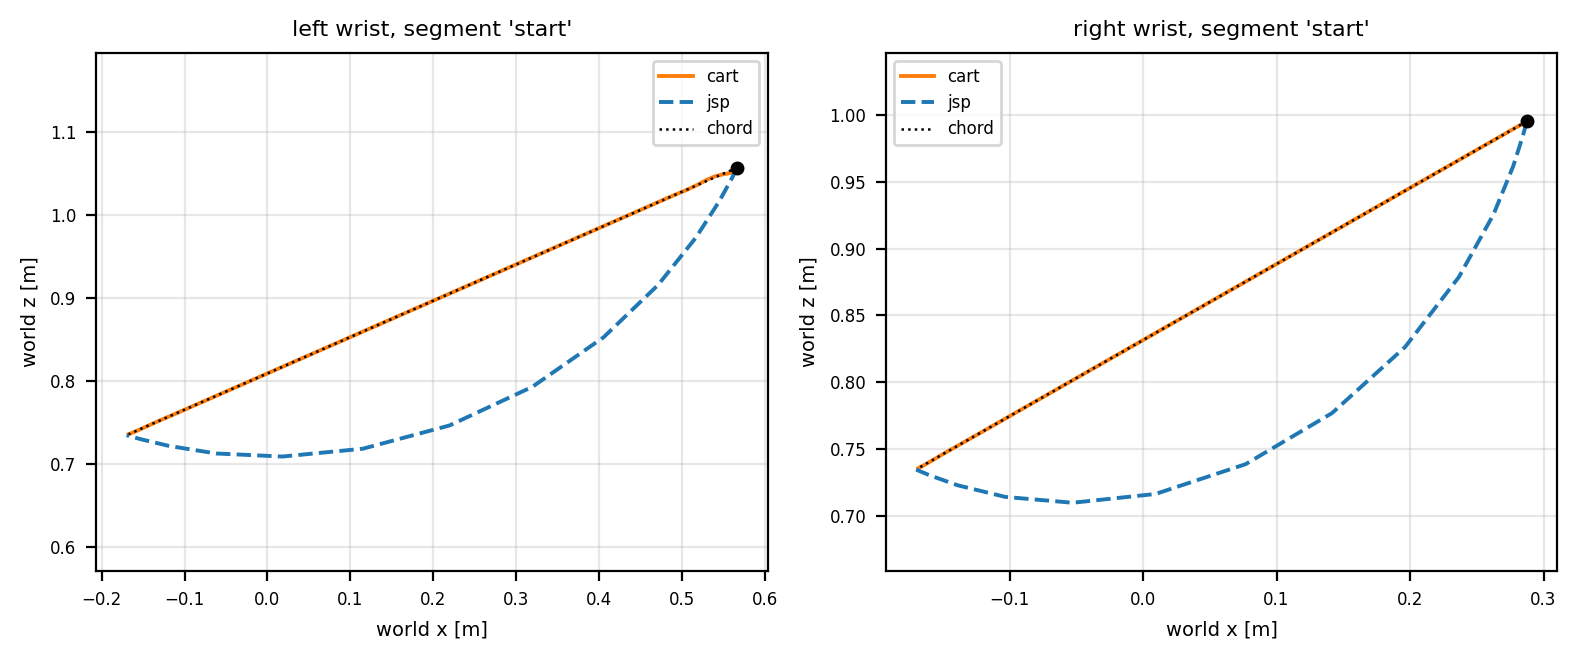


collision sweep (self + table), margin 0.050 m
   segment  route  samples  min dist [m]  at t [s]  pair                                     level
----------------------------------------------------------------------------------------------------
     start   cart       53       -0.0526      2.90  table_top <-> geom[32]                   COLLISION
              jsp       16       -0.0821      0.70  table_top <-> geom[30]                   COLLISION
     step1   cart       50        0.0741      2.50  geom[12] <-> geom[46]                    SAFE
              jsp       16        0.0742      0.30  geom[12] <-> geom[46]                    SAFE
     step2   cart       21        0.0896      1.20  geom[10] <-> geom[60]                    SAFE
              jsp       14        0.0896      0.60  geom[10] <-> geom[60]                    SAFE
     step3   cart       17        0.0365      1.60  geom[20] <-> geom[30]                    WARNING
              jsp       15        0.0365      1.40  g

In [37]:
# Offline check -- plan the sequence BOTH ways and put the two side by side

SEQUENCE_NAME = "bring_up"     # "bring_up" or "shut_down"

joint_speed_limits = SPEED_SCALE * get_sg2_joint_speed_limits(env=env, joint_names=command_joint_names)
joint_acc_limits   = SPEED_SCALE * get_sg2_joint_acc_limits(env=env, joint_names=command_joint_names)
plan_hz            = 10.0

print(f"revolute  v_max {SG2_MAX_REV_JOINT_SPEED*SPEED_SCALE:.4f} rad/s "
      f"({np.rad2deg(SG2_MAX_REV_JOINT_SPEED)*SPEED_SCALE:.1f} deg/s)"
      f" | a_max {SG2_MAX_REV_JOINT_ACC*SPEED_SCALE:.4f} rad/s^2")
print(f"prismatic v_max {SG2_MAX_PRI_JOINT_SPEED*SPEED_SCALE:.4f} m/s              | a_max {SG2_MAX_PRI_JOINT_ACC*SPEED_SCALE:.4f} m/s^2")
print(f"(every ceiling above carries SPEED_SCALE = {SPEED_SCALE:.2f})")
print(f"wrist     v_max {CART_LIN_SPEED_MAX:.4f} m/s              | {np.rad2deg(CART_ANG_SPEED_MAX):.1f} deg/s")
print(f"(acceleration is provisional: v_max / {SG2_JOINT_ACC_RAMP_SEC:.2f}s -- verify against the motor specs)\n")

# ---------------------------------------------------------------------------
# 1) Expand the waypoints by joint name and check them against the joint limits
# ---------------------------------------------------------------------------
step_names = SG2_MOTION_SEQUENCES[SEQUENCE_NAME]
# bring_up and shut_down read from different waypoint tables now, so pick by name.
waypoint_table = SG2_SHUTDOWN_WAYPOINTS if SEQUENCE_NAME == "shut_down" else SG2_BRINGUP_WAYPOINTS
waypoints  = [(name, expand_sg2_qpos(command_joint_names, waypoint_table[name]))
              for name in step_names]

all_ok = True
for name, q in waypoints:
    limit_info = check_sg2_joint_limits(env, command_joint_names, q)
    all_ok = all_ok and limit_info["ok"]
    nonzero = [f"{n}={v:+.4f}" for n, v in zip(command_joint_names, q) if abs(v) > 1e-9]
    print(f"[{name:>5s}] joint limits {'OK' if limit_info['ok'] else 'VIOLATED'} | {', '.join(nonzero)}")
    if not limit_info["ok"]:
        print(format_sg2_joint_limit_violations(limit_info))

# ---------------------------------------------------------------------------
# 2) Plan each segment in Cartesian space, with the joint-space plan alongside
# ---------------------------------------------------------------------------
# Both planners are seeded from the same pose at every segment, so the only
# difference between the two columns is the route.
#
# Read `gap` first. It is how far the pose the IK landed on at u=1 is from the
# stored waypoint, and it is not an error -- a 7-DoF arm has a null space, so
# "put the wrist here" does not name a single joint pose. A large gap means this
# segment's goal was never really a Cartesian instruction.
q_seg    = env.get_qpos(joint_names=command_joint_names)
segments = []
print(f"\nplanning {SEQUENCE_NAME}: current pose -> {' -> '.join(step_names)}")
print(f"{'segment':>10s} {'T cart':>7s} {'T jsp':>7s} {'x':>6s} {'D_lin':>7s} {'D_ang':>7s} "
      f"{'ik err':>8s} {'gap':>9s} {'v/v_max':>8s} {'a/a_max':>8s}  route")
print("-" * 104)

total_cart = total_jsp = 0.0
for name, q_goal in waypoints:
    traj = plan_cartesian_wrist(
        env = env, joint_names = command_joint_names,
        q_start = q_seg, q_goal = q_goal, ik_solvers = ik_solvers,
        v_max = joint_speed_limits, a_max = joint_acc_limits,
        hz = plan_hz, min_duration = 0.5, n_knot = CART_N_KNOT,)
    traj_jsp = plan_min_jerk(
        q_start = q_seg, q_goal = q_goal,
        v_max = joint_speed_limits, a_max = joint_acc_limits,
        hz = plan_hz, min_duration = 0.5,)

    # Differentiate the qpos array itself -- that array is all the loop consumes.
    # For this planner it is also the only check that matters: the qpos come out
    # of an IK solve, not out of a formula, so "within the limits" has to be
    # measured rather than assumed.
    dt_plan = 1.0 / plan_hz
    v_num   = np.diff(traj["qpos"], axis=0) / dt_plan
    a_num   = np.diff(v_num,        axis=0) / dt_plan
    v_ratio = np.abs(v_num) / joint_speed_limits[None, :]
    a_ratio = np.abs(a_num) / joint_acc_limits[None, :]
    flag = ("V!" if v_ratio.max() > 1.0 + 1e-6 else "") + ("A!" if a_ratio.max() > 1.0 + 1e-6 else "")
    all_ok = all_ok and v_ratio.max() <= 1.0 + 1e-6 and a_ratio.max() <= 1.0 + 1e-6

    # `param` is which path parameterization won the retime -- see cell 5. A segment
    # reading `arclength` is one whose duration used to be set by an IK null-space
    # spike rather than by any ceiling.
    route = f"cartesian:{traj['param']}" if traj["cartesian"] else f"joint-space ({traj['reason']})"
    print(f"{name:>10s} {traj['duration']:7.2f} {traj_jsp['duration']:7.2f} "
          f"{traj['duration'] / max(traj_jsp['duration'], 1e-9):5.2f}x "
          f"{traj['D_lin']:7.3f} {np.rad2deg(traj['D_ang']):6.1f}d "
          f"{traj['ik_err_max']:8.4f} {np.rad2deg(traj['endpoint_gap']):8.1f}d "
          f"{v_ratio.max():8.4f} {a_ratio.max():8.4f}  {route} {flag}")

    segments.append({"name": name, "traj": traj, "traj_jsp": traj_jsp})
    total_cart += traj["duration"]
    total_jsp  += traj_jsp["duration"]
    q_seg = q_goal

print("-" * 104)
print(f"{'total':>10s} {total_cart:7.2f} {total_jsp:7.2f} "
      f"{total_cart / max(total_jsp, 1e-9):5.2f}x")
print("ik err [m] = worst residual of the wrist coordinate targets over the knots.")
print("gap        = |IK pose at u=1 - stored waypoint|, the null-space drift this route accepts.")

# ---------------------------------------------------------------------------
# 3) What the two routes do to the wrist -- the whole point of this notebook
# ---------------------------------------------------------------------------
# Both plans end at the same wrist pose. What differs is the route: the Cartesian
# plan's bulge away from the straight line should be at the millimetre level (it
# is only the knot spacing and the IK residual), while the joint-space plan's
# bulge grows as the SQUARE of the joint displacement.
print(f"\nwrist route (max bulge away from the straight line between the endpoints)")
print(f"{'segment':>10s} {'hand':>6s} {'chord [m]':>10s} {'cart [mm]':>10s} {'jsp [mm]':>9s} {'jsp/chord':>10s}")
print("-" * 62)
for segment in segments:
    for label, key in (("cart", "traj"), ("jsp", "traj_jsp")):
        _, segment[f"path_{label}"] = wrist_path_from_qpos(
            env, command_joint_names, segment[key]["qpos"], n_max=200)
    for hand_type in SG2_HAND_TYPES:
        bulge_cart, chord = path_straightness(segment["path_cart"][hand_type])
        bulge_jsp,  _     = path_straightness(segment["path_jsp"][hand_type])
        if chord < 1e-4:
            continue
        # The Cartesian bulge is at the resolution of the knot spacing, so a
        # ratio against it is dividing by noise. Report both in millimetres and
        # scale the joint-space one by the chord instead -- that ratio is the
        # quantity that actually grows with the size of the move.
        print(f"{segment['name']:>10s} {hand_type:>6s} {chord:10.3f} {1e3 * bulge_cart:10.2f} "
              f"{1e3 * bulge_jsp:9.1f} {100.0 * bulge_jsp / chord:9.1f}%")
print("cart [mm] is the knot spacing and the IK residual, nothing else; jsp [mm] is the route.")

# The same thing as a picture, for the segment with the longest wrist travel.
worst_segment = max(
    segments,
    key=lambda seg: max(path_straightness(seg["path_jsp"][h])[1] for h in SG2_HAND_TYPES))
fig, axes = plt.subplots(1, len(SG2_HAND_TYPES), figsize=(4.0 * len(SG2_HAND_TYPES), 3.4))
for ax, hand_type in zip(np.atleast_1d(axes), SG2_HAND_TYPES):
    for label, style, color in (("cart", "-", "tab:orange"), ("jsp", "--", "tab:blue")):
        P = worst_segment[f"path_{label}"][hand_type]
        ax.plot(P[:, 0], P[:, 2], style, lw=1.4, color=color, label=label)
    P = worst_segment["path_cart"][hand_type]
    ax.plot([P[0, 0], P[-1, 0]], [P[0, 2], P[-1, 2]], ':', lw=0.9, color='k', label="chord")
    ax.plot(P[0, 0], P[0, 2], 'o', ms=4, color='k')
    ax.set_title(f"{hand_type} wrist, segment '{worst_segment['name']}'", fontsize=8)
    ax.set_xlabel("world x [m]", fontsize=7); ax.set_ylabel("world z [m]", fontsize=7)
    ax.set_aspect('equal', adjustable='datalim'); ax.grid(alpha=0.3); ax.legend(fontsize=6)
plt.tight_layout(); plt.show()

# ---------------------------------------------------------------------------
# 4) Sweep the planned path for collisions (self + table)
# ---------------------------------------------------------------------------
# A straight Cartesian line is not automatically a safe one -- it is only a
# predictable one. Lifting straight up out of the table is exactly what this
# route is for; sliding straight through the torso on a fold-in leg is exactly
# what it is not.
n_sweep_sample = 120
safe_margin    = 0.05

def geom_label(geom_idx):
    return env.geom_names[geom_idx] or f"geom[{geom_idx}]"

q_backup = env.get_qpos(joint_names=command_joint_names)
print(f"\ncollision sweep (self + table), margin {safe_margin:.3f} m")
print(f"{'segment':>10s} {'route':>6s} {'samples':>8s} {'min dist [m]':>13s} {'at t [s]':>9s}  {'pair':<40s} level")
print("-" * 100)
try:
    for segment in segments:
        for label, key in (("cart", "traj"), ("jsp", "traj_jsp")):
            traj   = segment[key]
            n_step = traj["qpos"].shape[0]
            idxs   = np.unique(np.linspace(0, n_step - 1, min(n_sweep_sample, n_step)).astype(int))
            worst  = None
            for step_idx in idxs:
                env.forward(q=traj["qpos"][step_idx], joint_names=command_joint_names)
                status = get_sg2_self_collision_status(
                    env                  = env,
                    collision_geom_pairs = collision_geom_pairs,
                    native_backend       = native_backend,
                    safe_margin          = safe_margin,
                    signed_distance_topk = 1,)
                if worst is None or status["min_signed_dist"] < worst["min_signed_dist"]:
                    worst = dict(status, t=float(traj["times"][step_idx]))
            info = worst["signed_distance_infos"][0] if worst["signed_distance_infos"] else None
            pair = ("%s <-> %s" % (geom_label(int(info["geom1_idx"])),
                                   geom_label(int(info["geom2_idx"])))) if info else "-"
            if label == "cart":
                all_ok = all_ok and worst["level"] != "collision"
            print(f"{segment['name'] if label == 'cart' else '':>10s} {label:>6s} {len(idxs):8d} "
                  f"{worst['min_signed_dist']:13.4f} {worst['t']:9.2f}  {pair:<40s} {worst['level'].upper()}")
finally:
    env.forward(q=q_backup, joint_names=command_joint_names)
print("-" * 100)
print("negative distance = the planned path goes through something; WARNING = within the margin.")
print("the `jsp` rows are the joint-space planner on the same segment, for comparison only.")

print(f"\nverdict: {'OK' if all_ok else 'FAILED -- see the flagged rows above'}")

**Viewer, wrist gizmos, command widget, executor**

One draggable gizmo per wrist (as in `sim_eef_controller_sg2_teleop.ipynb`), the command window,
and the `SG2MotionExecutor` that owns the output stage.

`SG2CartesianMotionExecutor` (defined above) reads its speed limits from `get_sg2_joint_speed_limits` and its acceleration
limits from `get_sg2_joint_acc_limits`, so nothing here needs a hand-picked number.

In [38]:
env.init_viewer(title="SG2 Motion Executor",x_offset=0.23,y_offset=0.00,width=0.77,height=1.0,fontscale=180)
env.viewer.set_cam_info(180.0,2.6,-18.0,[0.0,0.0,0.95])
env.viewer.set_transparency(transparent=True)

# One draggable gizmo per wrist, seeded at that wrist's current pose.
markers = {
    hand_type: InteractiveMarker(
        env          = env,
        T            = get_sg2_wrist_control_T(env,hand_type),
        axis_len     = 0.12,
        ring_r       = 0.12,
        control_mode = "pR",
        # The default is (0.03, 0.0): the hit test is deliberately shifted 3 cm along
        # the camera's right axis, so the point that actually grabs a handle sits to
        # the right of the cursor. Zero it out and the cyan dot follows the cursor.
        mouse_view_offset = (0.0, 0.0),)
    for hand_type in SG2_HAND_TYPES
}

# HiDPI guard. MuJoCoParser sets viewer._scale (framebuffer px per logical px) once,
# at window creation, and never again -- but it refreshes viewer.viewport from the
# live framebuffer on every render. Move the window between a Retina and an external
# display and the two disagree, which puts the marker hit test at a multiple of the
# real cursor position. sync_viewer_mouse_scale() re-reads it; the loop below calls
# it every render tick, so a window moved mid-session corrects itself.
import glfw

def sync_viewer_mouse_scale(env):
    window = env.viewer.window
    fb_w, _  = glfw.get_framebuffer_size(window)
    win_w, _ = glfw.get_window_size(window)
    scale = fb_w / max(1.0, win_w)
    changed = abs(scale - getattr(env.viewer, "_scale", scale)) > 1e-9
    env.viewer._scale = scale
    return scale, changed

scale, _ = sync_viewer_mouse_scale(env)
print(f"viewer mouse scale: {scale:.2f} (framebuffer px per logical px)")

def make_sg2_joint_overlay_text(env, joint_names, mode="rad"):
    """One line per joint group -- hinges in radians, the lift slide in metres.

    sim_joint_controller_sg2_teleop_with_table.ipynb prints the same block off
    its marker controller. There is no controller in this notebook, so the
    groups come straight from SG2_JOINT_MARKER_GROUPS and the values straight
    from MuJoCo. `mode="deg"` switches the hinges to degrees.
    """
    pri_joint_names = set(env.pri_joint_names)
    lines = []
    for group_key, group_joint_names in SG2_JOINT_MARKER_GROUPS.items():
        entries = []
        for joint_name in group_joint_names:
            if joint_name not in joint_names:
                continue
            qpos = float(env.get_qpos(joint_names=[joint_name])[0])
            if joint_name in pri_joint_names:
                entries.append("%.3fm" % qpos)
            else:
                entries.append("%.3f" % (qpos if mode == "rad" else np.rad2deg(qpos)))
        if entries:
            lines.append("%-6s: %s" % (group_key, " ".join(entries)))
    return "\n".join(lines)


ctrl_radio = create_sg2_motion_command_widget()

play_hz  = 100
# ik_solvers is a constructor argument here, not just something shut_down
# borrows: this planner runs IK on every segment it routes.
executor = SG2CartesianMotionExecutor(
    env                = env,
    joint_names        = command_joint_names,
    hz                 = play_hz,
    min_duration       = 0.5,
    # Same array for the plan and for the rate-limit clamp, so the two can never
    # disagree -- the real notebook wires it the same way.
    speed_limits       = SPEED_SCALE * get_sg2_joint_speed_limits(env=env, joint_names=command_joint_names),
    acc_limits         = SPEED_SCALE * get_sg2_joint_acc_limits(env=env, joint_names=command_joint_names),
    ik_solvers         = ik_solvers,
    cartesian_segments = CARTESIAN_SEGMENTS,
    n_knot             = CART_N_KNOT,)

print(f"executor joints ({len(executor.joint_names)}): {executor.joint_names}")
print(f"planner: plan_cartesian_wrist, {CART_N_KNOT} knots per segment per arm")
print(f"speed scale: {SPEED_SCALE:.2f} (revolute {np.rad2deg(SG2_MAX_REV_JOINT_SPEED)*SPEED_SCALE:.0f} deg/s, "
      f"wrist {CART_LIN_SPEED_MAX:.3f} m/s)")
print(f"motion commands: {list(SG2_MOTION_SEQUENCES)}")
for name, steps in SG2_MOTION_SEQUENCES.items():
    print(f"  {name:>10s}: {' -> '.join(steps)}")
print(f"qpos file: {SG2_JOINT_QPOS_PATH}")

viewer mouse scale: 2.00 (framebuffer px per logical px)
executor joints (19): ['lift_joint', 'head_joint1', 'head_joint2', 'arm_l_joint1', 'arm_l_joint2', 'arm_l_joint3', 'arm_l_joint4', 'arm_l_joint5', 'arm_l_joint6', 'arm_l_joint7', 'arm_r_joint1', 'arm_r_joint2', 'arm_r_joint3', 'arm_r_joint4', 'arm_r_joint5', 'arm_r_joint6', 'arm_r_joint7', 'gripper_l_joint1', 'gripper_r_joint1']
planner: plan_cartesian_wrist, 30 knots per segment per arm
speed scale: 2.00 (revolute 120 deg/s, wrist 0.300 m/s)
motion commands: ['bring_up', 'bring_up_origin', 'shut_down']
    bring_up: start -> step1 -> step2 -> step3 -> step4
  bring_up_origin: start -> step3 -> step4
   shut_down: step1 -> step2 -> step3 -> step4
qpos file: /Users/yongjoo/dev/VAI_AIWORKER/ri_motion_v5_VR/project/ffw_sg2_vr_teleoperation/qpos/sg2_joint_qpos.json


**Main loop**

Two timers in one loop: the executor ticks at 100Hz, rendering at 30Hz.

- **executor active** -> it owns the joints. The IK solve is skipped and every gizmo is re-seeded
  onto the wrist pose the executor just produced, so a gizmo left behind by an earlier drag
  cannot yank the arm back.
- **executor idle** -> the gizmos own the joints, exactly as in `sim_eef_controller_sg2_teleop`.

`executor.tick(dt=...)` is given the **measured** cycle time. `SimpleTimer.dt` is the constant
`1.0/Hz`, so on a loop that has fallen behind it under-reports and the rate limit clamps a motion
that was actually within spec; `sec_elps_diff` is the real interval. The executor clips it into
`[1/hz, 10/hz]` so one stalled tick cannot authorize a huge jump.

Rendering is the expensive part of this loop. If the timing report at the end shows well under
100Hz, drop `render_hz`.

Closing the viewer or the command window stops the loop.
**Planning is not free in this notebook.** Each Cartesian segment costs `CART_N_KNOT` IK solves
per arm -- roughly a second -- and segments are planned lazily, inside the first `tick()` of each,
so that second lands *during* the motion as a visible freeze between legs. It is plan time, not
control time: no IK runs on a tick that is playing back.


[Executor Render] Initialized with [10.0]HZ. MAX_SEC:[inf]sec.
[Executor Render] Start ([10.0]HZ. MAX_SEC:[inf]sec).
running. drag the wrist gizmos, then pick Motion -> bring_up / shut_down.
[Executor Render][1] run delayed! T:[100.0]ms run:[415.8]ms]
[Executor Render][2][0.4s] delayed! T:[100.0]ms interval:[419.0]ms prev_run:[415.8]ms.
[Executor Render][2] run delayed! T:[100.0]ms run:[248.9]ms]
[Executor Render][3][0.7s] delayed! T:[100.0]ms interval:[253.6]ms prev_run:[248.9]ms.
[Executor Render][3] run delayed! T:[100.0]ms run:[210.8]ms]
[Executor Render][4][0.9s] delayed! T:[100.0]ms interval:[211.4]ms prev_run:[210.8]ms.
[Executor Render][7] run delayed! T:[100.0]ms run:[100.1]ms]
[Executor Render][8] run delayed! T:[100.0]ms run:[112.3]ms]
[Executor Render][9][1.4s] delayed! T:[100.0]ms interval:[112.5]ms prev_run:[112.3]ms.
[Executor Render][9] run delayed! T:[100.0]ms run:[108.2]ms]
[Executor Render][10] run delayed! T:[100.0]ms run:[116.7]ms]
[Executor Render][11][1.6s] delay

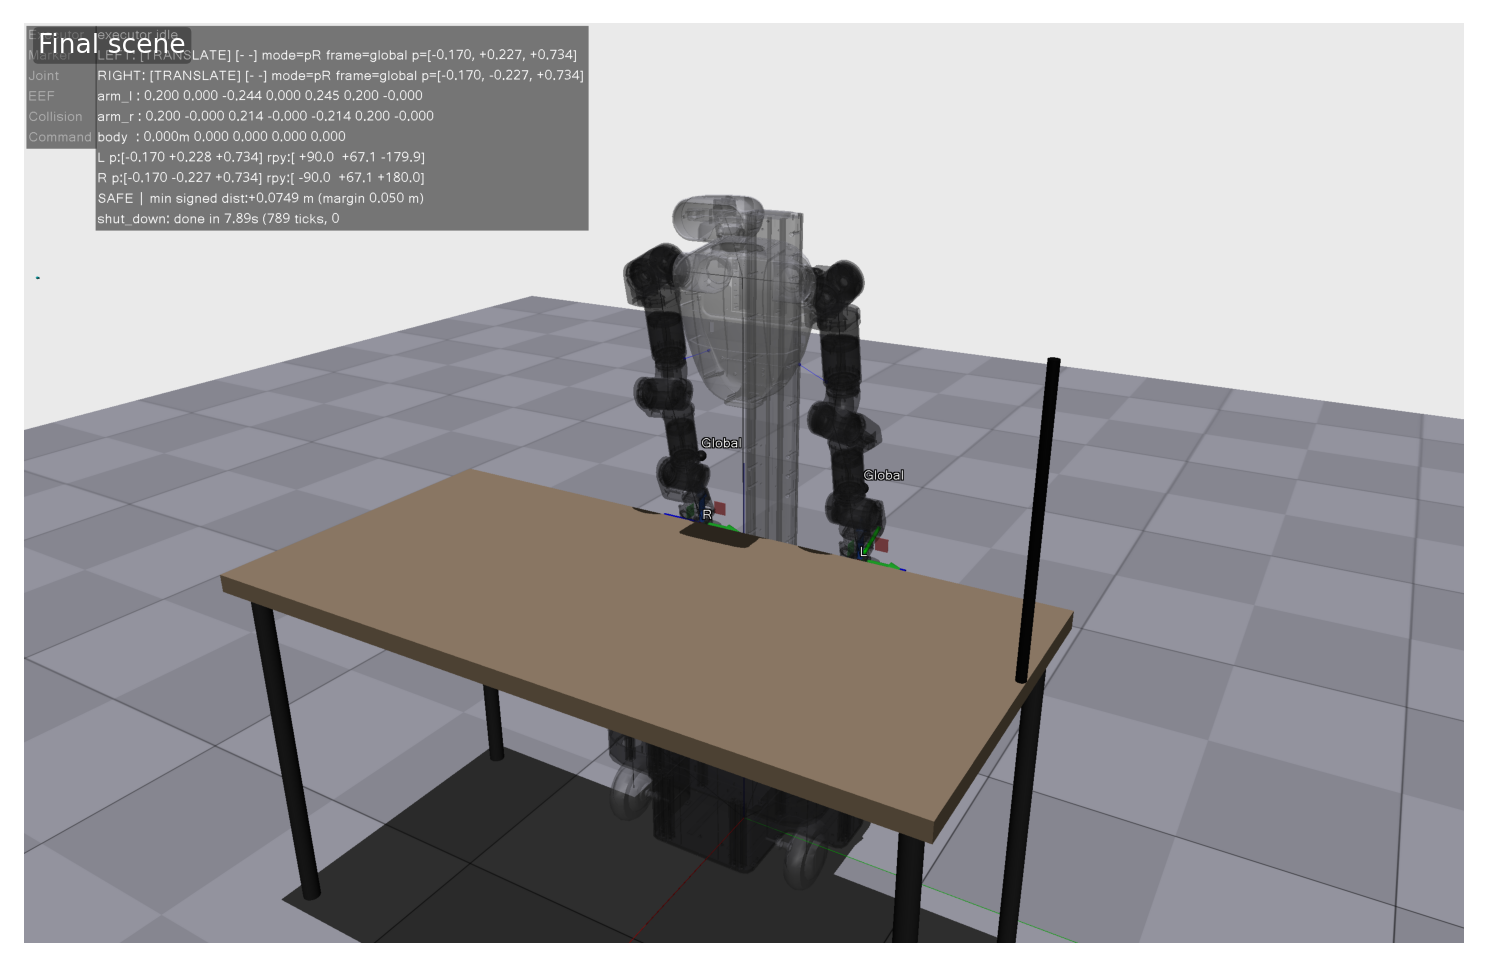

Done.


In [39]:
# Main loop -- wrist gizmo IK when idle, planned trajectory playback when a command is running

render_hz        = 10
collision_margin = 0.05        # shared by the live check and the analysis cell

tmr_exec   = SimpleTimer(name="Motion Executor", Hz=play_hz,   verbose=False)
tmr_render = SimpleTimer(name="Executor Render", Hz=render_hz, verbose=True)
tmr_exec.start()
tmr_render.start()
env.reset_wall_time(); env.reset_sim_time()

# Log of the most recent executed motion, consumed by the analysis cell below.
# Cleared whenever a new command starts, so a plot always shows one motion.
exec_log = {"t": [], "q_cmd": [], "q_use": [], "limited": [], "clipped": [],
            "dq_ratio": [], "dt": [], "segment": []}
exec_log_label = ""

# Closest-approach log, kept apart from exec_log because it is sampled at
# render_hz rather than per control tick -- a full signed-distance sweep at 100Hz
# would not fit in the loop. Empty when the Collision row was off.
coll_log = {"t": [], "min_dist": [], "level": [], "pair": [], "segment": []}

collision_status     = None
last_command_message = ""
was_active           = False
t_motion             = 0.0

print("running. drag the wrist gizmos, then pick Motion -> bring_up / shut_down.")

try:
    while env.is_viewer_alive() and ctrl_radio.isVisible():
        app.processEvents()

        # Read the widget once per loop pass, outside the timers, so a command
        # reacts on the pass it is clicked. (is_toggled consumes the event: a
        # second call in the same pass would miss it.)
        # ik_solvers is only used by shut_down's wrist-lift pre-step; without it
        # that step is skipped and the rest of the sequence still runs.
        command_info = handle_sg2_motion_command_widget(
            widget=ctrl_radio, executor=executor, ik_solvers=ik_solvers)
        if command_info["message"]:
            last_command_message = command_info["message"]
            print(f"[Command] {last_command_message}")
        if command_info["sync_requested"]:
            for hand_type, marker in markers.items():
                marker.set_T(get_sg2_wrist_control_T(env, hand_type), clear_state=True)

        # A newly started motion gets a fresh log.
        if executor.is_active and not was_active:
            exec_log = {key: [] for key in exec_log}
            coll_log = {key: [] for key in coll_log}
            exec_log_label = executor.label
            t_motion = 0.0
        was_active = executor.is_active

        # ------------------------------------------------------------------
        # 100Hz: the executor's control cycles for this pass
        # ------------------------------------------------------------------
        # `tick()` consumes ONE planned sample, and the plan is sampled at
        # play_hz. So a pass that takes longer than 1/play_hz stretches the
        # motion: at 100 Hz a T=2.87s plan is 287 samples, and a loop that only
        # completes ~30 passes a second plays it back over ~10s. The plan was
        # never wrong -- playback was running at the loop rate.
        #
        # So consume as many samples as the elapsed wall time actually covers.
        # This is NOT the same as skipping samples: every sample still goes
        # through tick(), so the rate limit and the joint clip see all of them
        # and the arm cannot jump. The cap keeps one long stall (a collision
        # sweep, a GC pause) from burning a whole segment in a single pass.
        #
        # The real notebook deliberately does NOT do this: there one tick is one
        # published ZMQ message, so catching up would publish a burst the robot
        # has no way to execute in the time it was given.
        EXEC_MAX_CATCH_UP = 20
        if tmr_exec.do_run():
            if executor.is_active:
                elapsed  = getattr(tmr_exec, "sec_elps_diff", None) or executor.dt_nominal
                n_ticks  = int(np.clip(round(elapsed * play_hz), 1, EXEC_MAX_CATCH_UP))
                for _ in range(n_ticks):
                    # Each sub-tick stands for one nominal sample period, which is
                    # the dt the plan was built against.
                    info = executor.tick(dt=executor.dt_nominal)
                    if info is None:
                        break
                    t_motion += info["dt"]
                    exec_log["t"       ].append(t_motion)
                    exec_log["q_cmd"   ].append(np.array(info["q_cmd"], dtype=np.float64))
                    exec_log["q_use"   ].append(np.array(info["q_use"], dtype=np.float64))
                    exec_log["limited" ].append(info["limited"])
                    exec_log["clipped" ].append(info["clipped"])
                    exec_log["dq_ratio"].append(info["max_dq_ratio"])
                    exec_log["dt"      ].append(info["dt"])
                    exec_log["segment" ].append(info["segment"])
                    if info["done"]:
                        last_command_message = (
                            f"{exec_log_label}: done in {t_motion:.2f}s "
                            f"({len(exec_log['t'])} ticks, "
                            f"{int(np.sum(exec_log['limited']))} rate limited, "
                            f"{int(np.sum(exec_log['clipped']))} clipped)")
                        print(f"[Command] {last_command_message}")
                        break
            tmr_exec.end()

        # ------------------------------------------------------------------
        # 30Hz: gizmo IK (only when the executor is idle) + draw
        # ------------------------------------------------------------------
        if tmr_render.do_run():
            # Re-read the HiDPI scale: viewer._scale is frozen at window creation,
            # so a window dragged to another display would otherwise leave the
            # marker hit test offset from the cursor.
            sync_viewer_mouse_scale(env)

            shown_hand_types = (
                list(SG2_HAND_TYPES) if command_info["show_hand"] == "all"
                else [command_info["show_hand"]]
            )

            if executor.is_active:
                # The executor owns the joints: no IK, and the gizmos follow the
                # wrists instead of commanding them.
                for hand_type, marker in markers.items():
                    marker.set_T(get_sg2_wrist_control_T(env, hand_type), clear_state=True)
            else:
                # Poll each gizmo's drag/hover state (no draw yet) so the IK solve
                # below sees the latest drag.
                wrist_targets_by_hand = {
                    hand_type: markers[hand_type].get_T(update=True, draw=False)
                    for hand_type in shown_hand_types
                }
                for hand_type, T_target in wrist_targets_by_hand.items():
                    solver = ik_solvers[hand_type]
                    solver.reset_buffers(env=env)
                    add_sg2_wrist_ik_coordinate_target(
                        ik_solver  = solver,
                        env        = env,
                        hand_type  = hand_type,
                        T_target   = T_target,
                        weight     = 1.0,
                        axis_width = 0.10,)
                    _,ik_info = solver.solve_ik(
                        env                     = env,
                        joint_limit_handle_flag = True,
                        nullspace_control_flag  = True,)
                    env.forward(q=ik_info["qpos_used_best"],joint_names=solver.joints_use)
                # The gizmos just moved the arms, so the executor's notion of the
                # last commanded pose is stale. Refresh it, or the first tick of the
                # next command would be rate-limited against a pose from minutes ago.
                executor.q_use = executor.get_qpos()

            # Same candidate pairs as the offline sweep, so this covers the table too.
            collision_status = None
            if command_info["check_collision"]:
                collision_status = get_sg2_self_collision_status(
                    env                  = env,
                    collision_geom_pairs = collision_geom_pairs,
                    native_backend       = native_backend,
                    safe_margin          = collision_margin,
                    signed_distance_topk = 5,)
                draw_sg2_self_collision(env,collision_status)

                # Record the closest pair while a motion is running: the overlay
                # only shows the current tick, so without this there is no way to
                # answer "how close did that shut_down come?" after the fact.
                if executor.is_active:
                    infos   = collision_status["signed_distance_infos"]
                    closest = min(infos, key=lambda info: info["signed_dist"]) if infos else None
                    coll_log["t"       ].append(t_motion)
                    coll_log["min_dist"].append(collision_status["min_signed_dist"])
                    coll_log["level"   ].append(collision_status["level"])
                    coll_log["segment" ].append(executor.segment_label)
                    # Body names, not geom names: the robot's collision geoms are
                    # unnamed in ffw_sg2.xml, so a geom-name label would read "? <-> table_top".
                    coll_log["pair"    ].append(
                        "%s <-> %s" % (closest["body1_name"], closest["body2_name"])
                        if closest is not None else "-")
            if command_info["show_eef"]:
                draw_sg2_wrist_frames(env)

            env.plot_global_coordinate_axes()
            env.plot_links_between_bodies(r=0.001)
            for hand_type in shown_hand_types:
                markers[hand_type].draw()

            env.viewer_text_overlay("Executor",executor.status_text(),loc="top left")
            env.viewer_text_overlay(
                "Marker",
                "\n".join(f"{hand_type.upper()}: {markers[hand_type].get_status()}"
                          for hand_type in shown_hand_types),
                loc="top left",)
            env.viewer_text_overlay(
                "Joint",
                make_sg2_joint_overlay_text(env, command_joint_names, mode="rad"),
                loc="top left",)
            if command_info["show_eef"]:
                env.viewer_text_overlay("EEF",make_sg2_eef_overlay_text(env),loc="top left")
            env.viewer_text_overlay("Collision",make_sg2_self_collision_overlay_text(collision_status),loc="top left")
            env.viewer_text_overlay("Command",last_command_message,loc="top left")
            env.render()
            tmr_render.end()
except KeyboardInterrupt:
    print("Interrupted.")
finally:
    ctrl_radio.close()
    env.close_viewer()
    if getattr(env,"final_rgb_img",None) is not None:
        imshow(env.final_rgb_img,fig_w=6,title="Final scene",title_fs=8)
    print("Done.")

**Analysis of the last executed motion**

The same six sections as `sim_motion_executor_test.ipynb`, plus one that only exists here.

- **position** and **velocity** for the joints that moved, with the two clipping stages kept apart.
  `rate limit` should be 0 and `joint limit clip` should be 0, as in the original -- but for a
  different reason. There, the plan was a formula built from `v_max`, so staying inside it was
  guaranteed by construction. Here the `qpos` come out of an IK solve, and staying inside the limits
  is the **result of the retiming step**, not a property of the formula. If `rate limit engaged` is
  non-zero in this notebook it means the retiming missed something, not that the loop fell behind.
- **wrist height and vertical speed**, from replaying the logged `q_use` through FK, with a
  straightness table underneath. This is the section the notebook exists for. On a `shut_down`, the
  `wrist_lift` band should show `z` rising along a clean ramp with a bulge of a few millimetres,
  against the centimetres the joint-space route produces for the same endpoints.
- **per-segment breakdown** -- which leg ran at its ceiling and which joint set the pace.
- **what the planner decided**, one row per segment: whether it was routed in Cartesian space at all,
  the straight-line distance, the worst IK residual, and the **endpoint gap**. That last column is
  the one to watch. It is how far the pose the IK landed on is from the stored waypoint, and it is
  not an error -- it is the null-space freedom this route accepts. Small on `wrist_lift`, whose goal
  only ever meant "wrist here"; tens of degrees on the stow legs, where the joint pose was the point.
  A large gap that keeps growing across the fold-in legs is the signal to set `CARTESIAN_SEGMENTS` to
  `{"wrist_lift"}`.
- **closest approach**, sampled at `render_hz` while the executor was active. Read it against the
  same run of `sim_motion_executor_test.ipynb`: a straight line out of the table should clear it by
  more, a straight line across the body by less. **Nothing here stops the motion** -- the check is
  report-only.

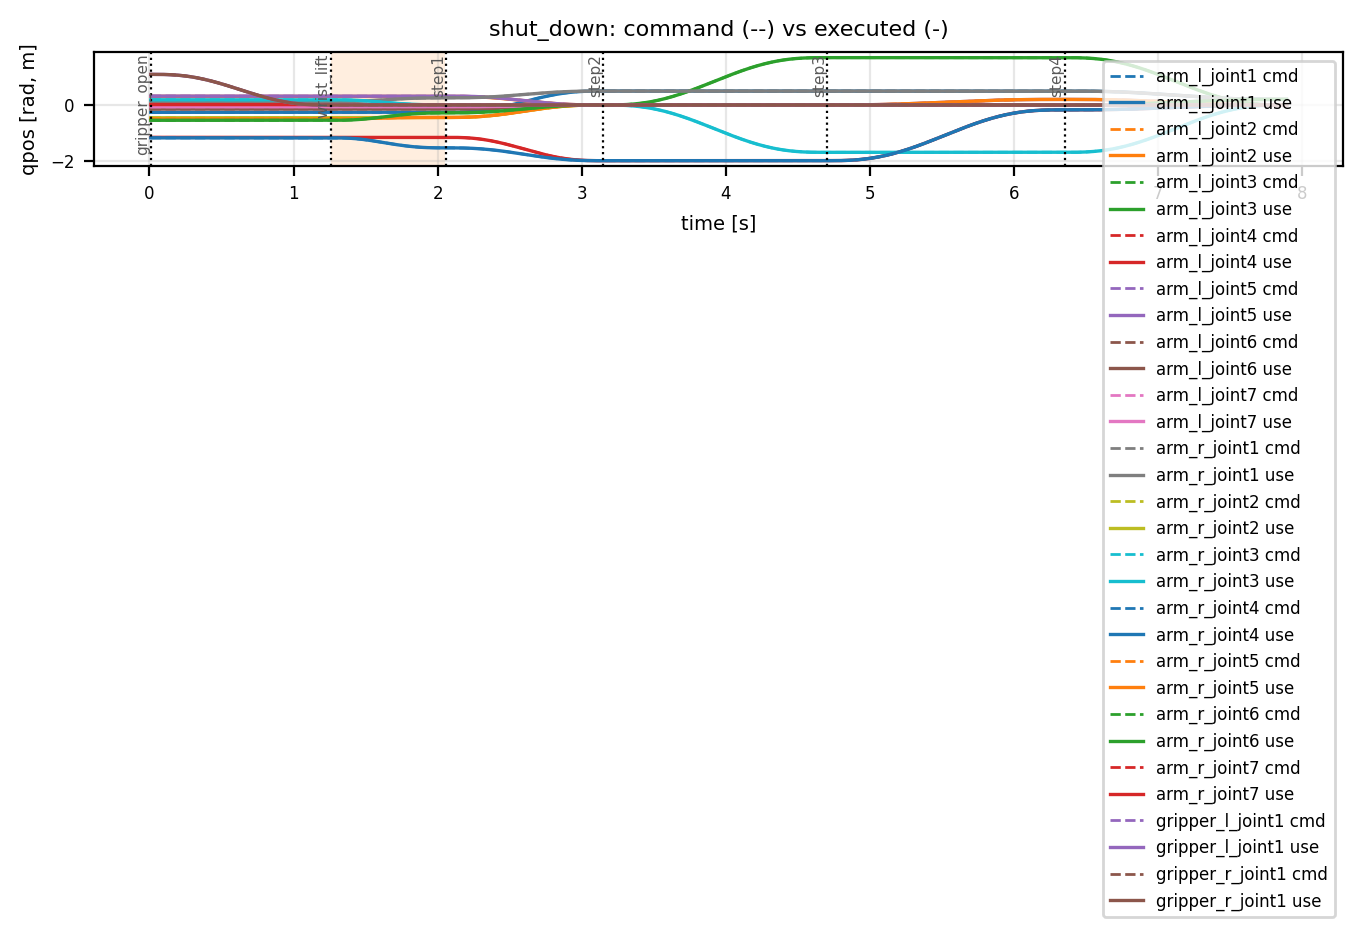

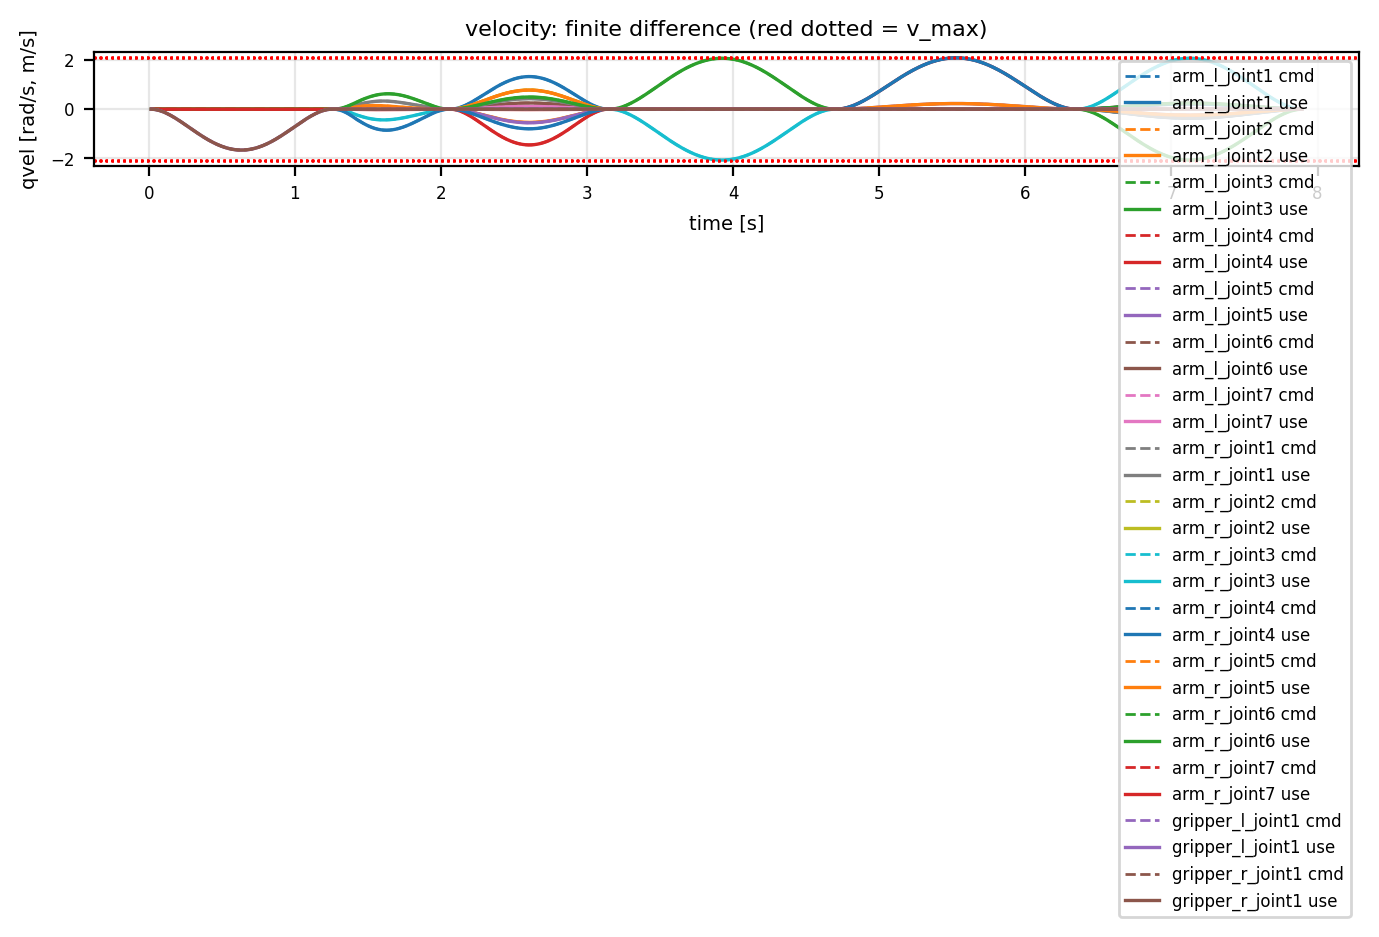

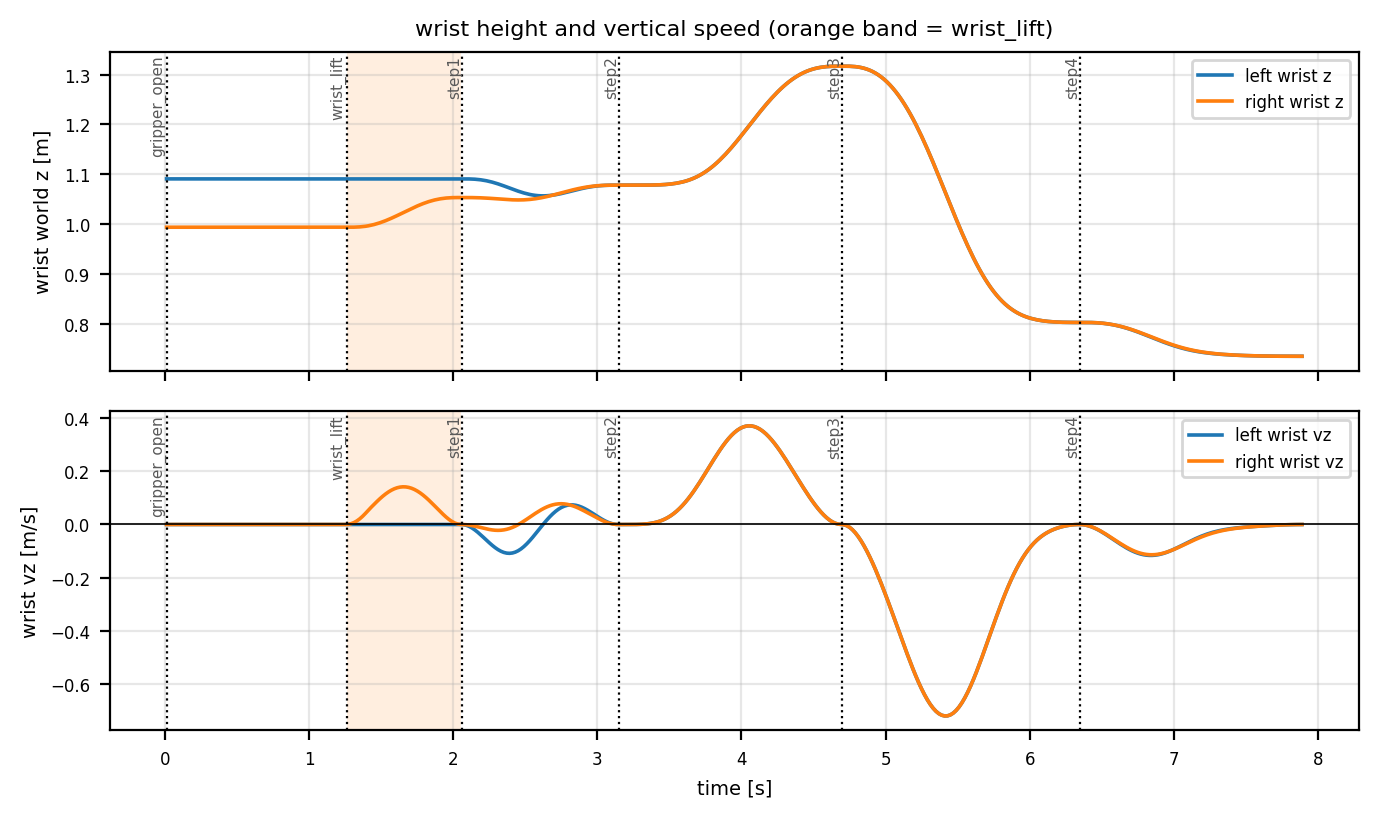

wrist lift          : t=1.26..2.05s (0.79s of a 7.89s motion)
  left  z 1.091 -> 1.091 m (rise +0.000 m), peak |vz| 0.000 m/s
  right z 0.993 -> 1.053 m (rise +0.060 m), peak |vz| 0.142 m/s

       segment   hand  chord [m]  bulge [mm]  bulge/chord
---------------------------------------------------------
    wrist_lift  right      0.060         0.0         0.0%
         step1   left      0.249        36.9        14.8%
         step1  right      0.165        17.4        10.5%
         step2   left      0.663       150.0        22.6%
         step2  right      0.663       150.0        22.6%
         step3   left      0.670       164.3        24.5%
         step3  right      0.670       164.3        24.5%
         step4   left      0.205        14.6         7.1%
         step4  right      0.205        13.2         6.4%

       segment  T [s]  ticks  v/v_max  a/a_max     pace-setting joint   its travel
------------------------------------------------------------------------------------
  

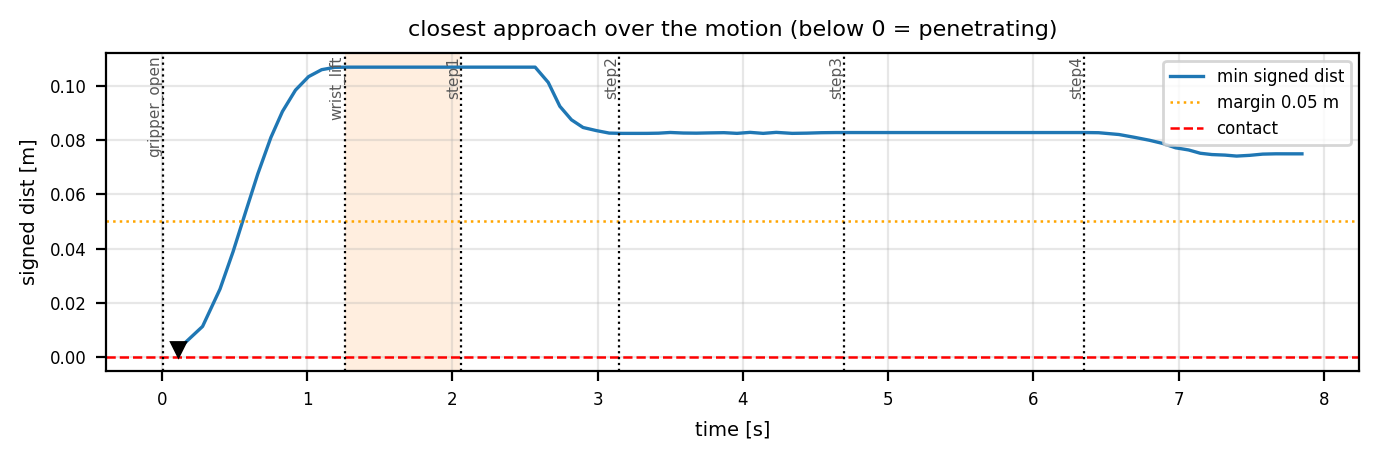


verdict: OK -- the planned trajectory respected both limits on its own.
         Note the wrist_lift row in the per-segment table: it runs at v_max like every other segment, so if it looked violent the cause is its travel, not a planner fault. Shorten it by capping the lift height, or slow it by raising min_duration for that segment.


In [40]:
# Analysis -- per-joint position/velocity plots, and the two clipping stages kept apart

if len(exec_log["t"]) < 3:
    raise RuntimeError("No motion logged. Run the loop cell and trigger a Motion command first.")

log_t     = np.array(exec_log["t"], dtype=np.float64)
log_q_cmd = np.array(exec_log["q_cmd"], dtype=np.float64)
log_q_use = np.array(exec_log["q_use"], dtype=np.float64)
log_dt    = np.array(exec_log["dt"], dtype=np.float64)

# Finite-difference velocity, using each tick's own dt rather than a nominal 1/hz.
dt_step = np.maximum(np.diff(log_t), 1e-9)[:, None]
qv_use  = np.diff(log_q_use, axis=0) / dt_step
qv_cmd  = np.diff(log_q_cmd, axis=0) / dt_step

# Plot only the joints that actually moved; all 19 at once is unreadable.
moved_idxs = np.where(np.max(np.abs(log_q_use - log_q_use[0]), axis=0) > 1e-6)[0]
if len(moved_idxs) == 0:
    moved_idxs = np.arange(min(2, log_q_use.shape[1]))

pri_joint_name_set = set(env.pri_joint_names)

# Segment spans (label, t_start, t_end). Marking only where a change happened
# leaves an 8-leg shut_down as 7 anonymous vertical lines, with no way to tell
# which one is the aggressive leg; the spans are what let each be named on the
# axis and shaded.
seg_labels    = list(exec_log["segment"])
segment_spans = []
span_start    = 0
for i in range(1, len(seg_labels) + 1):
    if i == len(seg_labels) or seg_labels[i] != seg_labels[span_start]:
        segment_spans.append((seg_labels[span_start], float(log_t[span_start]), float(log_t[i - 1])))
        span_start = i

# The Cartesian pre-step of shut_down, highlighted everywhere: it is the one
# segment whose goal was not a stored waypoint but an IK solve made at command
# time, and therefore the one that can surprise.
HIGHLIGHT_SEGMENT = "wrist_lift"

def draw_segments(ax):
    """Name every segment on the time axis and shade the wrist-lift leg."""
    for name, t0, t1 in segment_spans:
        ax.axvline(t0, color='k', ls=':', lw=0.8)
        if name == HIGHLIGHT_SEGMENT:
            ax.axvspan(t0, t1, color='tab:orange', alpha=0.13, lw=0, zorder=0)
        ax.text(t0, 0.99, name, transform=ax.get_xaxis_transform(), rotation=90,
                va='top', ha='right', fontsize=5.5, color='0.35')

# ---------------------------------------------------------------------------
# 1) Position
# ---------------------------------------------------------------------------
plt.figure(figsize=(7, 3))
for idx in moved_idxs:
    line, = plt.plot(log_t, log_q_cmd[:, idx], '--', lw=1.0,
                     label=f"{command_joint_names[idx]} cmd")
    plt.plot(log_t, log_q_use[:, idx], '-', lw=1.2, color=line.get_color(),
             label=f"{command_joint_names[idx]} use")
draw_segments(plt.gca())
plt.xlabel("time [s]", fontsize=7); plt.ylabel("qpos [rad, m]", fontsize=7)
plt.title(f"{exec_log_label}: command (--) vs executed (-)", fontsize=8)
plt.legend(fontsize=6); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

# ---------------------------------------------------------------------------
# 2) Velocity, with the limit drawn in
# ---------------------------------------------------------------------------
plt.figure(figsize=(7, 3))
for idx in moved_idxs:
    line, = plt.plot(log_t[1:], qv_cmd[:, idx], '--', lw=1.0,
                     label=f"{command_joint_names[idx]} cmd")
    plt.plot(log_t[1:], qv_use[:, idx], '-', lw=1.2, color=line.get_color(),
             label=f"{command_joint_names[idx]} use")
    plt.axhline( joint_speed_limits[idx], color='r', ls=':', lw=0.8)
    plt.axhline(-joint_speed_limits[idx], color='r', ls=':', lw=0.8)
plt.xlabel("time [s]", fontsize=7); plt.ylabel("qvel [rad/s, m/s]", fontsize=7)
plt.title("velocity: finite difference (red dotted = v_max)", fontsize=8)
plt.legend(fontsize=6); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

# ---------------------------------------------------------------------------
# 3) Where the wrists actually went -- the Cartesian path behind the joint plots
# ---------------------------------------------------------------------------
# `wrist_lift` is the only segment specified in Cartesian space ("raise world z
# to the height `step4` has") but executed in joint space, so the qpos plots
# above cannot answer the question that step exists to answer: how far, and how
# fast, did the wrist actually go up? Replay the logged q_use through FK to find
# out -- `env.forward` is kinematics only, so this costs nothing, and the pose
# the cell started from is put back afterwards.
n_fk_max  = 600                                  # FK on every tick of a 30s log is wasteful
fk_stride = max(1, int(np.ceil(len(log_t) / n_fk_max)))
fk_idxs   = np.arange(0, len(log_t), fk_stride)
fk_t      = log_t[fk_idxs]

q_before = env.get_qpos(joint_names=command_joint_names).copy()
try:
    wrist_p = {hand_type: np.zeros((len(fk_idxs), 3)) for hand_type in SG2_HAND_TYPES}
    for row, idx in enumerate(fk_idxs):
        env.forward(q=log_q_use[idx], joint_names=command_joint_names)
        for hand_type in SG2_HAND_TYPES:
            wrist_p[hand_type][row] = t2p(get_sg2_wrist_control_T(env, hand_type))
finally:
    env.forward(q=q_before, joint_names=command_joint_names)

fig, axes = plt.subplots(2, 1, figsize=(7, 4.2), sharex=True)
for hand_type in SG2_HAND_TYPES:
    z  = wrist_p[hand_type][:, 2]
    vz = np.gradient(z, fk_t)                    # vertical speed of the wrist itself
    axes[0].plot(fk_t, z,  '-', lw=1.3, label=f"{hand_type} wrist z")
    axes[1].plot(fk_t, vz, '-', lw=1.3, label=f"{hand_type} wrist vz")
for ax in axes:
    draw_segments(ax)
    ax.grid(alpha=0.3); ax.legend(fontsize=6)
axes[1].axhline(0.0, color='k', lw=0.6)
axes[0].set_ylabel("wrist world z [m]", fontsize=7)
axes[1].set_ylabel("wrist vz [m/s]", fontsize=7)
axes[1].set_xlabel("time [s]", fontsize=7)
axes[0].set_title("wrist height and vertical speed (orange band = wrist_lift)", fontsize=8)
plt.tight_layout(); plt.show()

lift_spans = [span for span in segment_spans if span[0] == HIGHLIGHT_SEGMENT]
if len(lift_spans) == 0:
    print("wrist lift          : no wrist_lift segment in this motion -- either it was not a "
          "shut_down, or both wrists were already at or above the lift height.")
else:
    _, lift_t0, lift_t1 = lift_spans[0]
    in_lift = (fk_t >= lift_t0) & (fk_t <= lift_t1)
    print(f"wrist lift          : t={lift_t0:.2f}..{lift_t1:.2f}s "
          f"({lift_t1 - lift_t0:.2f}s of a {log_t[-1]:.2f}s motion)")
    for hand_type in SG2_HAND_TYPES:
        z = wrist_p[hand_type][in_lift, 2]
        if len(z) < 2:
            continue
        vz = np.gradient(z, fk_t[in_lift])
        # The rise is not a constant "small lift": it is (step4 wrist z) - (wrist z
        # at command time), so a hand left down by the table gets tens of cm.
        print(f"  {hand_type:<5s} z {z[0]:.3f} -> {z[-1]:.3f} m (rise {z[-1] - z[0]:+.3f} m), "
              f"peak |vz| {np.max(np.abs(vz)):.3f} m/s")

# How straight was each leg? Both planners end a segment at the same wrist pose,
# so the endpoints carry no information -- the bulge away from the chord between
# them is the whole difference between one route and another.
print()
print(f"{'segment':>14s} {'hand':>6s} {'chord [m]':>10s} {'bulge [mm]':>11s} {'bulge/chord':>12s}")
print("-" * (14 + 43))
for name, t0, t1 in segment_spans:
    m = (fk_t >= t0) & (fk_t <= t1)
    if int(np.sum(m)) < 3:
        continue
    for hand_type in SG2_HAND_TYPES:
        bulge, chord = path_straightness(wrist_p[hand_type][m])
        if chord < 1e-4:
            continue
        print(f"{name:>14s} {hand_type:>6s} {chord:10.3f} {1e3 * bulge:11.1f} "
              f"{100.0 * bulge / chord:11.1f}%")

# ---------------------------------------------------------------------------
# 4) Per-segment breakdown -- which leg of the motion is the aggressive one
# ---------------------------------------------------------------------------
# `estimate_duration` returns the SHORTEST T that still respects v_max and a_max,
# so every segment is planned to run at its ceiling. "Aggressive" is therefore
# never a limit violation here (v/v_max stays ~1.0 throughout); it is a segment
# whose joint-space displacement is much larger than its Cartesian displacement
# looks. This table names the joint that set the pace and how far it travelled.
# Both ratios are finite differences of the executed qpos and carry the same
# noise as the plots above -- read them as "about 1.0 or not", not to 3 digits.
qa_use = np.diff(qv_use, axis=0) / dt_step[1:]

print()
print(f"{'segment':>14s} {'T [s]':>6s} {'ticks':>6s} {'v/v_max':>8s} {'a/a_max':>8s} "
      f"{'pace-setting joint':>22s} {'its travel':>12s}")
print("-" * 84)
for name, t0, t1 in segment_spans:
    m = (log_t >= t0) & (log_t <= t1)
    if int(np.sum(m)) < 3:
        print(f"{name:>14s} {t1 - t0:6.2f} {int(np.sum(m)):6d} {'-':>8s} {'-':>8s}")
        continue
    v_ratio = np.abs(qv_use[m[1:]]) / joint_speed_limits
    a_ratio = np.abs(qa_use[m[2:]]) / joint_acc_limits
    j       = int(np.argmax(np.max(v_ratio, axis=0)))
    travel  = float(np.max(np.abs(log_q_use[m][:, j] - log_q_use[m][0, j])))
    travel_text = (f"{1e3 * travel:7.1f} mm" if command_joint_names[j] in pri_joint_name_set
                   else f"{np.rad2deg(travel):7.1f} deg")
    print(f"{name:>14s} {t1 - t0:6.2f} {int(np.sum(m)):6d} "
          f"{np.max(v_ratio):8.2f} {np.max(a_ratio):8.2f} "
          f"{command_joint_names[j]:>22s} {travel_text:>12s}")

# ---------------------------------------------------------------------------
# 4b) What the planner decided, segment by segment
# ---------------------------------------------------------------------------
# `endpoint_gap` and `ik_err_max` exist only at plan time and are gone by the
# time the motion is over, so the executor keeps them. The gap is not an error:
# a 7-DoF arm has a null space, so "put the wrist here" does not name a single
# joint pose. It IS the signal for whether a segment's goal was a Cartesian
# instruction at all -- small on wrist_lift, large on the stow waypoints.
if len(getattr(executor, "plan_reports", [])) > 0:
    print()
    print(f"{'segment':>14s} {'route':>12s} {'T [s]':>6s} {'D_lin':>7s} {'D_ang':>7s} "
          f"{'ik err [m]':>11s} {'gap [deg]':>10s}  note")
    print("-" * 92)
    for report in executor.plan_reports:
        route = "cartesian" if report["cartesian"] else "joint-space"
        print(f"{report['segment']:>14s} {route:>12s} {report['duration']:6.2f} "
              f"{report['D_lin']:7.3f} {np.rad2deg(report['D_ang']):6.1f}d "
              f"{report['ik_err_max']:11.4f} {np.rad2deg(report['endpoint_gap']):9.1f}d  "
              f"{report['reason']}")
    print("-" * 92)
    print("gap = |IK pose at the end of the segment - the stored waypoint|. Tens of degrees on a")
    print("      stow leg means that leg belongs on the joint-space planner: set CARTESIAN_SEGMENTS.")

# ---------------------------------------------------------------------------
# 5) The two clipping stages, reported separately
# ---------------------------------------------------------------------------
n_tick    = len(log_t)
n_limited = int(np.sum(exec_log["limited"]))
n_clipped = int(np.sum(exec_log["clipped"]))
gap       = np.abs(log_q_cmd - log_q_use)

print(f"motion              : {exec_log_label}  ({' -> '.join(dict.fromkeys(exec_log['segment']))})")
print(f"ticks               : {n_tick} over {log_t[-1]:.2f} s")
print(f"loop timing         : dt median {1e3 * np.median(log_dt):.1f} ms "
      f"(nominal {1e3 / play_hz:.1f} ms) -> effective {1.0 / np.median(log_dt):.1f} Hz")
print(f"rate limit engaged  : {n_limited} / {n_tick} ticks ({100.0 * n_limited / n_tick:.1f}%), "
      f"max dq/dq_max {np.max(exec_log['dq_ratio']):.3f}x")
print(f"joint limit clipped : {n_clipped} / {n_tick} ticks ({100.0 * n_clipped / n_tick:.1f}%)")
print()
print(f"{'joint':<20s} {'max |cmd-use|':>14s} {'deg / mm':>14s}")
for idx in np.argsort(-np.max(gap, axis=0))[:5]:
    value = float(np.max(gap[:, idx]))
    unit  = f"{1e3 * value:10.4f} mm" if command_joint_names[idx] in pri_joint_name_set \
            else f"{np.rad2deg(value):10.4f} deg"
    print(f"{command_joint_names[idx]:<20s} {value:14.3e} {unit:>14s}")

# ---------------------------------------------------------------------------
# 6) How close the motion came to a collision (self + table)
# ---------------------------------------------------------------------------
# Sampled at render_hz while the executor was active, so the resolution is
# coarser than the position plots above -- it answers "how close did it come",
# not "at exactly which millisecond".
if len(coll_log["t"]) == 0:
    print("collision           : not logged -- the Collision row was off during this motion.")
else:
    coll_t    = np.array(coll_log["t"], dtype=np.float64)
    coll_dist = np.array(coll_log["min_dist"], dtype=np.float64)
    finite    = np.isfinite(coll_dist)
    n_warn    = int(np.sum(np.array(coll_log["level"]) == "warning"))
    n_hit     = int(np.sum(np.array(coll_log["level"]) == "collision"))

    if not np.any(finite):
        print(f"collision           : {len(coll_t)} samples, no candidate pair ever in range")
    else:
        worst = int(np.nanargmin(np.where(finite, coll_dist, np.inf)))
        print(f"collision samples   : {len(coll_t)} at ~{render_hz} Hz "
              f"({n_warn} within margin, {n_hit} penetrating)")
        print(f"closest approach    : {coll_dist[worst]:+.4f} m at t={coll_t[worst]:.2f}s "
              f"during [{coll_log['segment'][worst]}]")
        print(f"                      {coll_log['pair'][worst]}")

        plt.figure(figsize=(7, 2.4))
        plt.plot(coll_t, coll_dist, '-', lw=1.2, color='tab:blue', label="min signed dist")
        plt.axhline(collision_margin, color='orange', ls=':', lw=0.9, label=f"margin {collision_margin:.2f} m")
        plt.axhline(0.0, color='r', ls='--', lw=0.9, label="contact")
        plt.plot(coll_t[worst], coll_dist[worst], 'v', color='k', ms=5)
        draw_segments(plt.gca())
        plt.xlabel("time [s]", fontsize=7); plt.ylabel("signed dist [m]", fontsize=7)
        plt.title("closest approach over the motion (below 0 = penetrating)", fontsize=8)
        plt.legend(fontsize=6); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

print()
if len(coll_log["t"]) > 0 and int(np.sum(np.array(coll_log["level"]) == "collision")) > 0:
    print("verdict: the motion PENETRATED something -- see the closest-approach row above. "
          "Nothing stopped it: the collision check is report-only.")
elif n_clipped > 0:
    print("verdict: the GOAL was out of range -- np.clip truncated it. "
          "Fix the waypoint; the offline check cell names the joint.")
elif n_limited > 0:
    print("verdict: the RATE LIMIT engaged -- the loop fell behind and dt hit the executor's "
          f"ceiling ({1e3 * executor.dt_max:.0f} ms). Lower render_hz.")
else:
    print("verdict: OK -- the planned trajectory respected both limits on its own.")
    # "Within the limits" and "gentle" are different claims, and only the first is
    # checked above. Say so, rather than letting an OK verdict imply the second.
    if len(lift_spans) > 0:
        print("         Note the wrist_lift row in the per-segment table: it runs at v_max like "
              "every other segment, so if it looked violent the cause is its travel, not a "
              "planner fault. Shorten it by capping the lift height, or slow it by raising "
              "min_duration for that segment.")